In [2]:
import torch
torch.cuda.is_available()

True

In [3]:
torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 5070'

In [5]:
%pip install pandas numpy

  Using cached pandas-2.3.3-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Using cached pytz-2025.2-py2.py3-none-any.whl.metadata (22 kB)
Using cached pandas-2.3.3-cp312-cp312-win_amd64.whl (11.0 MB)
Using cached pytz-2025.2-py2.py3-none-any.whl (509 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
# STEP 0.1 — Basic environment sanity + load CSV (no external installs)

import sys
import platform
from pathlib import Path
import pandas as pd  # (pandas is commonly installed; if not, you'll see an error)

DATA_PATH = r"E:\CSE 495 Project\comments_only.csv"

print("Python:", sys.version)
print("Platform:", platform.platform())

p = Path(DATA_PATH)
print("File exists:", p.exists())
print("File size (MB):", round(p.stat().st_size / (1024**2), 2) if p.exists() else None)

# Read a small sample first (fast + safe for huge files)
df_head = pd.read_csv(DATA_PATH, nrows=20, encoding_errors="ignore")
print("\nColumns:", list(df_head.columns))
print("\nPreview (first 5 rows):")
display(df_head.head())


Python: 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
File exists: True
File size (MB): 343.8

Columns: ['Comments']

Preview (first 5 rows):


,Comments
0,আমি তো প্রথমেই হেসে দিলাম
1,🌹
2,আমি নাটক মুভি এসব দেখি আর প্রজেক্ট করি না হলে ...
3,@সে_আমার_নয়_তাও_কেনো_এতো_মায়া_হয়_😅❤️‍🩹
4,অনিবার্য মৃত্যুকেও ততটা ভালোবাসিনি অনিশ্চিত তো...


In [7]:
# STEP 0.3 — Count rows safely + basic integrity check

import pandas as pd

DATA_PATH = r"E:\CSE 495 Project\comments_only.csv"

# Count rows without loading entire file into memory
row_count = sum(1 for _ in open(DATA_PATH, encoding="utf-8", errors="ignore")) - 1
print("Total rows:", row_count)

# Load a slightly larger random sample for inspection
sample_df = pd.read_csv(
    DATA_PATH,
    usecols=["Comments"],
    nrows=5000,
    encoding_errors="ignore"
)

print("\nSample shape:", sample_df.shape)
print("Null values:", sample_df["Comments"].isna().sum())

print("\nRandom examples:")
display(sample_df.sample(10, random_state=42))


Total rows: 2230328

Sample shape: (5000, 1)
Null values: 0

Random examples:


,Comments
1501,নানী নাতি কোথায় হারিয়ে গেলো ইত্যাদি থেকে
2586,বরিশালের মেহেন্দিগন্জে ইত্যাদির একটা পর্ব চাই
2653,"নিজ উপজেলায় ইত্যাদি হয়েছে,, উপস্থিত হতে পারি..."
1055,সারা বিশ্বের সেরা বিনোদন অনুষ্ঠান
705,ভোলায় জম্ম গ্রহন কড়ে নিজকে অনেক ধন্য মনে কড়ি
106,হিমি আপুর ফ্যানরা লাইক দিন 👍❤️👍👍 👍
589,প্রিয় জন্মভূমিতে স্বাগতম।
2468,চরফ্যাশের আছো কেউ
2413,ইত্যাদি অনুষ্ঠান অনেক ভালো লাগে
1600,ইত্যাদি জন্মস্থান ভোলা❤❤❤❤❤


In [8]:
# STEP 0.4 — CTIC experiment configuration (NO computation)

from dataclasses import dataclass

@dataclass(frozen=True)
class CTICConfig:
    # Data
    data_path: str
    text_column: str

    # Embedding
    encoder_name: str
    embedding_dim: int | None  # auto if model decides

    # UMAP (clustering-only)
    umap_n_components: int
    umap_metric: str
    umap_random_state: int

    # HDBSCAN
    min_cluster_size: int
    min_samples: int | None
    cluster_metric: str

    # Representative selection
    reps_per_cluster: int

    # Cross-lingual refinement
    alpha: float
    tau: float
    refinement_iters: int


CONFIG = CTICConfig(
    # Data
    data_path=r"E:\CSE 495 Project\comments_only.csv",
    text_column="Comments",

    # Embedding (locked for BN–EN shared space)
    encoder_name="sentence-transformers/LaBSE",
    embedding_dim=None,

    # UMAP
    umap_n_components=10,   # safe middle of [5, 15]
    umap_metric="cosine",
    umap_random_state=42,

    # HDBSCAN
    min_cluster_size=50,    # conservative for 2M social comments
    min_samples=None,      # let HDBSCAN infer
    cluster_metric="euclidean",

    # Representatives
    reps_per_cluster=30,   # translation budget control

    # Refinement
    alpha=0.7,             # start BN-heavy
    tau=0.30,              # confidence threshold
    refinement_iters=3
)

print(CONFIG)


CTICConfig(data_path='E:\\CSE 495 Project\\comments_only.csv', text_column='Comments', encoder_name='sentence-transformers/LaBSE', embedding_dim=None, umap_n_components=10, umap_metric='cosine', umap_random_state=42, min_cluster_size=50, min_samples=None, cluster_metric='euclidean', reps_per_cluster=30, alpha=0.7, tau=0.3, refinement_iters=3)


In [9]:
# STAGE 1 — STEP 1.1
# Install minimal preprocessing libraries

%pip install regex tqdm emoji


     ---------------------------------------- 0.0/41.5 kB ? eta -:--:--
     -------------------------------------  41.0/41.5 kB 960.0 kB/s eta 0:00:01
     -------------------------------------- 41.5/41.5 kB 665.7 kB/s eta 0:00:00
  Using cached tqdm-4.67.1-py3-none-any.whl.metadata (57 kB)
   ---------------------------------------- 0.0/277.1 kB ? eta -:--:--
   ---------------------------------------- 277.1/277.1 kB 8.3 MB/s eta 0:00:00
Using cached tqdm-4.67.1-py3-none-any.whl (78 kB)
   ---------------------------------------- 0.0/608.4 kB ? eta -:--:--
   --------------------------------------- 608.4/608.4 kB 19.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import regex
import emoji
from tqdm import tqdm

print("regex OK")
print("emoji OK")
print("tqdm OK")


regex OK
emoji OK
tqdm OK


In [11]:
# STAGE 1 — STEP 1.2
# Basic text cleaning (safe, reversible)

import regex as re

# URL pattern
URL_PATTERN = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)

# HTML tag pattern
HTML_PATTERN = re.compile(r"<.*?>")

# Multiple whitespace
WHITESPACE_PATTERN = re.compile(r"\s+")


def clean_text_basic(text: str) -> str:
    if not isinstance(text, str):
        return ""

    # Remove URLs
    text = URL_PATTERN.sub("", text)

    # Remove HTML
    text = HTML_PATTERN.sub("", text)

    # Normalize whitespace
    text = WHITESPACE_PATTERN.sub(" ", text)

    return text.strip()


# --- Quick sanity test on sample ---
test_samples = [
    "আমি তো প্রথমেই হেসে দিলাম",
    "Visit https://example.com এখনই!",
    "<b>ইত্যাদি</b> অনুষ্ঠান ❤️",
    "   অনেক    ফাঁকা      জায়গা   ",
]

for s in test_samples:
    print("ORIG:", s)
    print("CLEAN:", clean_text_basic(s))
    print("-" * 40)


ORIG: আমি তো প্রথমেই হেসে দিলাম
CLEAN: আমি তো প্রথমেই হেসে দিলাম
----------------------------------------
ORIG: Visit https://example.com এখনই!
CLEAN: Visit এখনই!
----------------------------------------
ORIG: <b>ইত্যাদি</b> অনুষ্ঠান ❤️
CLEAN: ইত্যাদি অনুষ্ঠান ❤️
----------------------------------------
ORIG:    অনেক    ফাঁকা      জায়গা   
CLEAN: অনেক ফাঁকা জায়গা
----------------------------------------


In [12]:
# STAGE 1 — STEP 1.3
# Bangla-aware normalization (safe + optional)

import unicodedata

# Zero-width characters commonly seen in Bangla text
ZERO_WIDTH_CHARS = [
    "\u200b",  # zero width space
    "\u200c",  # zero width non-joiner
    "\u200d",  # zero width joiner
    "\ufeff",  # BOM
]

def normalize_bangla(text: str) -> str:
    if not isinstance(text, str):
        return ""

    # Unicode normalization
    text = unicodedata.normalize("NFC", text)

    # Remove zero-width characters
    for zw in ZERO_WIDTH_CHARS:
        text = text.replace(zw, "")

    return text.strip()


# --- Test normalization ---
test_samples = [
    "বাংলা\u200bভাষা",
    "আমি\u200cভালো",
    "ইত্যাদি অনুষ্ঠান",
]

for s in test_samples:
    print("ORIG:", repr(s))
    print("NORM:", repr(normalize_bangla(s)))
    print("-" * 40)


ORIG: 'বাংলা\u200bভাষা'
NORM: 'বাংলাভাষা'
----------------------------------------
ORIG: 'আমি\u200cভালো'
NORM: 'আমিভালো'
----------------------------------------
ORIG: 'ইত্যাদি অনুষ্ঠান'
NORM: 'ইত্যাদি অনুষ্ঠান'
----------------------------------------


In [13]:
# STAGE 1 — STEP 1.4
# Emoji detection utilities

import emoji
import regex as re

# Pattern to match any emoji
EMOJI_PATTERN = re.compile(
    "[\U0001F300-\U0001FAFF\U00002700-\U000027BF]"
)

def count_emojis(text: str) -> int:
    return sum(1 for ch in text if ch in emoji.EMOJI_DATA)

def strip_emojis(text: str) -> str:
    return "".join(ch for ch in text if ch not in emoji.EMOJI_DATA)

def is_emoji_only(text: str) -> bool:
    if not isinstance(text, str):
        return False
    text_no_space = text.strip()
    if not text_no_space:
        return False
    return strip_emojis(text_no_space) == ""

def is_emoji_dominant(text: str, ratio: float = 0.6) -> bool:
    if not isinstance(text, str):
        return False
    if len(text.strip()) == 0:
        return False
    emoji_count = count_emojis(text)
    return (emoji_count / max(len(text), 1)) >= ratio


# --- Tests ---
test_samples = [
    "🌹",
    "❤️😂🔥",
    "ইত্যাদি অনুষ্ঠান ❤️❤️",
    "আমি ভালো আছি 😊",
    "সাধারণ লেখা",
]

for s in test_samples:
    print(s)
    print("emoji_only:", is_emoji_only(s))
    print("emoji_dominant:", is_emoji_dominant(s))
    print("-" * 40)


🌹
emoji_only: True
emoji_dominant: True
----------------------------------------
❤️😂🔥
emoji_only: False
emoji_dominant: True
----------------------------------------
ইত্যাদি অনুষ্ঠান ❤️❤️
emoji_only: False
emoji_dominant: False
----------------------------------------
আমি ভালো আছি 😊
emoji_only: False
emoji_dominant: False
----------------------------------------
সাধারণ লেখা
emoji_only: False
emoji_dominant: False
----------------------------------------


In [14]:
# STAGE 1 — STEP 1.5
# Script detection (Bangla / Latin / Mixed / Other)

import regex as re

# Unicode ranges
BANGLA_PATTERN = re.compile(r"\p{Script=Bengali}")
LATIN_PATTERN = re.compile(r"\p{Script=Latin}")

def detect_script(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return "other"

    has_bn = bool(BANGLA_PATTERN.search(text))
    has_lat = bool(LATIN_PATTERN.search(text))

    if has_bn and has_lat:
        return "mixed"
    elif has_bn:
        return "bangla"
    elif has_lat:
        return "latin"
    else:
        return "other"


# --- Tests ---
test_samples = [
    "আমি ভালো আছি",
    "ami valo achi",
    "আমি valo achi",
    "❤️😂🔥",
    "12345 !!!",
    "@user_name",
]

for s in test_samples:
    print(repr(s), "→", detect_script(s))


'আমি ভালো আছি' → bangla
'ami valo achi' → latin
'আমি valo achi' → mixed
'❤️😂🔥' → other
'12345 !!!' → other
'@user_name' → latin


In [15]:
# STAGE 1 — STEP 1.6
# Apply preprocessing pipeline chunk-wise and save output

import pandas as pd
from tqdm import tqdm

INPUT_PATH = CONFIG.data_path
OUTPUT_PATH = r"E:\CSE 495 Project\comments_preprocessed.csv"

CHUNK_SIZE = 50_000  # safe for most machines

processed_chunks = []

reader = pd.read_csv(
    INPUT_PATH,
    usecols=[CONFIG.text_column],
    chunksize=CHUNK_SIZE,
    encoding_errors="ignore"
)

for chunk in tqdm(reader, desc="Preprocessing"):
    text = chunk[CONFIG.text_column].astype(str)

    cleaned = text.apply(clean_text_basic).apply(normalize_bangla)

    out = pd.DataFrame({
        "text_raw": text,
        "text_clean": cleaned,
        "script": cleaned.apply(detect_script),
        "emoji_only": cleaned.apply(is_emoji_only),
        "emoji_dominant": cleaned.apply(is_emoji_dominant),
    })

    processed_chunks.append(out)

# Save incrementally
pd.concat(processed_chunks, ignore_index=True).to_csv(
    OUTPUT_PATH, index=False, encoding="utf-8-sig"
)

print("Saved to:", OUTPUT_PATH)


Preprocessing: 41it [00:44,  1.08s/it]


Saved to: E:\CSE 495 Project\comments_preprocessed.csv


In [17]:
!pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
# STAGE 2 — STEP 2.1b
# Verify CUDA + GPU availability

import torch

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA capability:", torch.cuda.get_device_capability(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))


Torch version: 2.9.1+cu128
CUDA available: True
GPU name: NVIDIA GeForce RTX 5070
CUDA capability: (12, 0)
GPU memory (GB): 12.82


In [19]:
%pip install sentence-transformers

     ---------------------------------------- 0.0/44.0 kB ? eta -:--:--
     ---------------------------------------- 44.0/44.0 kB 1.1 MB/s eta 0:00:00
     ---------------------------------------- 0.0/60.8 kB ? eta -:--:--
     ---------------------------------------- 60.8/60.8 kB 3.2 MB/s eta 0:00:00
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/493.7 kB ? eta -:--:--
   --------------------------------------- 493.7/493.7 kB 15.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
    --------------------------------------- 0.2/12.0 MB 5.0 MB/s eta 0:00:03
   --- ------------------------------------ 1.2/12.0 MB 12.4 MB/s eta 0:00:01
   ------- -------------------------------- 2.2/12.0 MB 17.7 MB/s eta 0:00:01
   ------- -------------------------------- 2.3/12.0 MB 13.3 MB/s eta 0:00:01
   -------- ------------------------------- 2.5/12.0 MB 11.5 MB/s eta 0:00:01
   ---------- ---


[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
# STAGE 2 — STEP 2.2b
# Load LaBSE on GPU + sanity check

from sentence_transformers import SentenceTransformer
import torch

model_name = CONFIG.encoder_name

print("Loading model:", model_name)
model = SentenceTransformer(model_name, device="cuda")

# Confirm model device
print("Model device:", next(model.parameters()).device)

# Tiny sanity test (Bangla + English)
test_sentences = [
    "আমি ভালো আছি",
    "ইত্যাদি অনুষ্ঠান অনেক ভালো লাগে",
    "I am feeling good today",
    "This show is very popular",
    "❤️😂🔥"
]

embeddings = model.encode(
    test_sentences,
    batch_size=8,
    convert_to_numpy=True,
    show_progress_bar=False
)

print("Embedding shape:", embeddings.shape)
print("Example cosine similarity (BN vs EN):")

import numpy as np
from numpy.linalg import norm

def cosine(a, b):
    return np.dot(a, b) / (norm(a) * norm(b))

print("BN–EN similarity:",
      round(cosine(embeddings[0], embeddings[2]), 3))


Loading model: sentence-transformers/LaBSE


modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/114 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/2.36M [00:00<?, ?B/s]

Model device: cuda:0
Embedding shape: (5, 768)
Example cosine similarity (BN vs EN):
BN–EN similarity: 0.691


In [21]:
# STAGE 2 — STEP 2.3
# Full dataset embedding with LaBSE (GPU, chunked, resumable)

import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from sentence_transformers import SentenceTransformer

# Paths
INPUT_PATH = r"E:\CSE 495 Project\comments_preprocessed.csv"
OUT_DIR = r"E:\CSE 495 Project\embeddings"
os.makedirs(OUT_DIR, exist_ok=True)

EMB_PATH = os.path.join(OUT_DIR, "embeddings.npy")
IDX_PATH = os.path.join(OUT_DIR, "embeddings_index.csv")

# Parameters
CHUNK_SIZE = 20_000
BATCH_SIZE = 128

# Load model (already cached)
model = SentenceTransformer(CONFIG.encoder_name, device="cuda")

# Determine resume point
start_row = 0
if os.path.exists(IDX_PATH):
    start_row = pd.read_csv(IDX_PATH).shape[0]
    print(f"Resuming from row {start_row}")

# Prepare output files
if start_row == 0:
    np.save(EMB_PATH, np.empty((0, 768), dtype=np.float32))
    pd.DataFrame({"row_id": []}).to_csv(IDX_PATH, index=False)

# Stream data
reader = pd.read_csv(
    INPUT_PATH,
    usecols=["text_clean"],
    chunksize=CHUNK_SIZE,
    skiprows=range(1, start_row + 1) if start_row > 0 else None
)

for chunk_id, chunk in enumerate(tqdm(reader, desc="Embedding chunks")):
    texts = chunk["text_clean"].astype(str).tolist()

    emb = model.encode(
        texts,
        batch_size=BATCH_SIZE,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=False
    ).astype(np.float32)

    # Append embeddings
    old = np.load(EMB_PATH)
    new = np.vstack([old, emb])
    np.save(EMB_PATH, new)

    # Append index
    idx_df = pd.DataFrame({"row_id": range(start_row, start_row + len(emb))})
    idx_df.to_csv(IDX_PATH, mode="a", index=False, header=False)

    start_row += len(emb)

    # Safety flush
    del emb, new, old

print("Embedding complete.")
print("Saved embeddings to:", EMB_PATH)
print("Saved index to:", IDX_PATH)


Embedding chunks: 101it [25:51, 15.36s/it]

Embedding complete.
Saved embeddings to: E:\CSE 495 Project\embeddings\embeddings.npy
Saved index to: E:\CSE 495 Project\embeddings\embeddings_index.csv


In [24]:
# STAGE 3 — STEP 3.1
# Install clustering dependencies

%pip install umap-learn hdbscan scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
import umap
import hdbscan
import sklearn
import pkg_resources

print("umap version:", umap.__version__)
print("hdbscan version:", pkg_resources.get_distribution("hdbscan").version)
print("sklearn version:", sklearn.__version__)


umap version: 0.5.9.post2
hdbscan version: 0.8.41
sklearn version: 1.8.0


C:\Users\AL AMIN\AppData\Local\Temp\ipykernel_8344\1201334410.py:4: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources


In [28]:
# STAGE 3 — STEP 3.2a (FIXED)
# Fit UMAP on a random sample (scalable)

import os
import numpy as np
import umap
import joblib

EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
OUT_DIR = r"E:\CSE 495 Project\umap"
os.makedirs(OUT_DIR, exist_ok=True)

UMAP_MODEL_PATH = os.path.join(OUT_DIR, "umap_model.joblib")
SAMPLE_IDX_PATH = os.path.join(OUT_DIR, "umap_fit_sample_idx.npy")
SAMPLE_U_PATH = os.path.join(OUT_DIR, "umap_fit_sample_10d.npy")

# Load embeddings as memmap
Z = np.load(EMB_PATH, mmap_mode="r")
N = Z.shape[0]
print("Embedding shape:", Z.shape)

# Choose a fit sample size (safe default)
FIT_N = 250_000  # increase later if you have lots of RAM
rng = np.random.default_rng(42)
sample_idx = rng.choice(N, size=FIT_N, replace=False)
sample_idx.sort()  # sorted indices are faster for memmap reads

Z_fit = np.array(Z[sample_idx], dtype=np.float32)  # bring only the sample into RAM
print("Fit sample shape:", Z_fit.shape)

# Fit UMAP on sample only
reducer = umap.UMAP(
    n_components=CONFIG.umap_n_components,
    metric=CONFIG.umap_metric,
    random_state=CONFIG.umap_random_state,
    low_memory=True,
    verbose=True
)

print("Fitting UMAP on sample...")
U_fit = reducer.fit_transform(Z_fit)
print("U_fit shape:", U_fit.shape)

# Save artifacts
joblib.dump(reducer, UMAP_MODEL_PATH)
np.save(SAMPLE_IDX_PATH, sample_idx)
np.save(SAMPLE_U_PATH, U_fit.astype(np.float32))

print("Saved UMAP model to:", UMAP_MODEL_PATH)
print("Saved sample indices to:", SAMPLE_IDX_PATH)
print("Saved sample UMAP to:", SAMPLE_U_PATH)

Embedding shape: (2008208, 768)
Fit sample shape: (250000, 768)
Fitting UMAP on sample...
UMAP(angular_rp_forest=True, metric='cosine', n_components=10, n_jobs=1, random_state=42, verbose=True)


E:\CSE 495 Project\env1\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Sat Dec 20 04:16:30 2025 Construct fuzzy simplicial set
Sat Dec 20 04:16:31 2025 Finding Nearest Neighbors
Sat Dec 20 04:16:31 2025 Building RP forest with 30 trees
Sat Dec 20 04:16:55 2025 NN descent for 18 iterations
	 1  /  18
	 2  /  18
	 3  /  18
	 4  /  18
	 5  /  18
	 6  /  18
	 7  /  18
	Stopping threshold met -- exiting after 7 iterations
Sat Dec 20 04:17:33 2025 Finished Nearest Neighbor Search
Sat Dec 20 04:17:36 2025 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Sat Dec 20 04:23:14 2025 Finished embedding
U_fit shape: (250000, 10)
Sat Dec 20 04:23:25 2025 Worst tree score: 0.31817200
Sat Dec 20 04:23:25 2025 Mean tree score: 0.32743800
Sat Dec 20 04:23:25 2025 Best tree score: 0.35750400
Sat Dec 20 04:23:30 2025 Forward diversification reduced edges from 3750000 to 1528784
Sat Dec 20 04:23:33 2025 Reverse diversification reduced edges from 1528784 to 1528784
Sat Dec 20 04:23:35 2025 Degree pruning reduced edges from 1799212 to 1795937
Sat Dec 20 04:23:35 2025 Resorting data and graph based on tree order
Sat Dec 20 04:23:35 2025 Building and compiling search function
Saved UMAP model to: E:\CSE 495 Project\umap\umap_model.joblib
Saved sample indi

In [29]:
# STAGE 3 — STEP 3.2b
# Transform full dataset with trained UMAP (chunk-wise, safe)

import os
import numpy as np
import joblib
from tqdm import tqdm

# Paths
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
UMAP_MODEL_PATH = r"E:\CSE 495 Project\umap\umap_model.joblib"
OUT_DIR = r"E:\CSE 495 Project\umap"
os.makedirs(OUT_DIR, exist_ok=True)

UMAP_OUT_PATH = os.path.join(OUT_DIR, "umap_10d.npy")

# Parameters
CHUNK_SIZE = 50_000

# Load embeddings (memmap) and model
Z = np.load(EMB_PATH, mmap_mode="r")
reducer = joblib.load(UMAP_MODEL_PATH)

N = Z.shape[0]
print("Total points:", N)

# Prepare output memmap
U = np.memmap(
    UMAP_OUT_PATH,
    dtype="float32",
    mode="w+",
    shape=(N, CONFIG.umap_n_components)
)

# Transform in chunks
start = 0
for start in tqdm(range(0, N, CHUNK_SIZE), desc="UMAP transform"):
    end = min(start + CHUNK_SIZE, N)
    Z_chunk = np.array(Z[start:end], dtype=np.float32)
    U[start:end] = reducer.transform(Z_chunk)

# Flush to disk
del U
print("UMAP transform complete.")
print("Saved full UMAP embeddings to:", UMAP_OUT_PATH)


Sat Dec 20 04:25:05 2025 Building and compiling search function
Total points: 2008208


UMAP transform:   0%|                                                                           | 0/41 [00:00<?, ?it/s]

Epochs completed:   0%|            0/30 [00:00]

	completed  0  /  30 epochs
	completed  3  /  30 epochs
	completed  6  /  30 epochs
	completed  9  /  30 epochs
	completed  12  /  30 epochs
	completed  15  /  30 epochs
	completed  18  /  30 epochs
	completed  21  /  30 epochs
	completed  24  /  30 epochs
	completed  27  /  30 epochs


UMAP transform:   2%|█▋                                                                 | 1/41 [00:15<10:05, 15.13s/it]

Epochs completed:   0%|            0/30 [00:00]

... (131 outputs left out)

Epochs completed:   0%|            0/100 [00:00]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs


UMAP transform: 100%|██████████████████████████████████████████████████████████████████| 41/41 [08:56<00:00, 13.08s/it]

	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs
UMAP transform complete.
Saved full UMAP embeddings to: E:\CSE 495 Project\umap\umap_10d.npy


In [31]:
# STAGE 4 — STEP 4.1 (FIXED)
# Load UMAP embeddings correctly (memmap)

import numpy as np

UMAP_PATH = r"E:\CSE 495 Project\umap\umap_10d.npy"

N = 2008208          # number of rows (from embeddings)
D = 10               # UMAP dimensions

U = np.memmap(
    UMAP_PATH,
    dtype="float32",
    mode="r",
    shape=(N, D)
)

print("UMAP shape:", U.shape)
print("UMAP dtype:", U.dtype)

# Sanity check: NaN / Inf on a sample
sample_idx = np.random.choice(N, size=10_000, replace=False)
U_sample = U[sample_idx]

print("NaN count (sample):", np.isnan(U_sample).sum())
print("Inf count (sample):", np.isinf(U_sample).sum())


UMAP shape: (2008208, 10)
UMAP dtype: float32
NaN count (sample): 0
Inf count (sample): 0


In [32]:
# STAGE 4 — STEP 4.2
# Run HDBSCAN baseline clustering

import hdbscan
import numpy as np
import pandas as pd
import os
from tqdm import tqdm

# Paths
UMAP_PATH = r"E:\CSE 495 Project\umap\umap_10d.npy"
OUT_DIR = r"E:\CSE 495 Project\clusters"
os.makedirs(OUT_DIR, exist_ok=True)

LABELS_PATH = os.path.join(OUT_DIR, "labels_hdbscan.npy")

# Known shape
N = 2008208
D = CONFIG.umap_n_components

# Load UMAP memmap
U = np.memmap(
    UMAP_PATH,
    dtype="float32",
    mode="r",
    shape=(N, D)
)

print("Running HDBSCAN...")
print("min_cluster_size:", CONFIG.min_cluster_size)
print("min_samples:", CONFIG.min_samples)

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=CONFIG.min_cluster_size,
    min_samples=CONFIG.min_samples,
    metric=CONFIG.cluster_metric,
    cluster_selection_method="eom",
    core_dist_n_jobs=1  # safer for memory
)

labels = clusterer.fit_predict(U)

# Save labels
np.save(LABELS_PATH, labels.astype(np.int32))

# Quick stats
n_noise = np.sum(labels == -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

print("Clustering complete.")
print("Total points:", len(labels))
print("Clusters found:", n_clusters)
print("Noise points:", n_noise, f"({n_noise / len(labels) * 100:.2f}%)")
print("Saved labels to:", LABELS_PATH)


Running HDBSCAN...
min_cluster_size: 50
min_samples: None
Clustering complete.
Total points: 2008208
Clusters found: 4206
Noise points: 1098036 (54.68%)
Saved labels to: E:\CSE 495 Project\clusters\labels_hdbscan.npy


In [33]:
# STAGE 5 — STEP 5.1
# Load embeddings and labels + cluster statistics

import numpy as np
import pandas as pd

# Paths
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_PATH = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"

# Load
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_PATH)

print("Embeddings shape:", Z.shape)
print("Labels shape:", labels.shape)

# Sanity alignment check
assert Z.shape[0] == labels.shape[0], "Embedding/label row mismatch!"

# Cluster size distribution (excluding noise)
labels_series = pd.Series(labels)
cluster_sizes = labels_series[labels_series != -1].value_counts()

print("Number of clusters:", cluster_sizes.shape[0])
print("Min cluster size:", cluster_sizes.min())
print("Median cluster size:", int(cluster_sizes.median()))
print("Mean cluster size:", int(cluster_sizes.mean()))
print("Max cluster size:", cluster_sizes.max())

display(cluster_sizes.head(10))


Embeddings shape: (2008208, 768)
Labels shape: (2008208,)
Number of clusters: 4206
Min cluster size: 50
Median cluster size: 121
Mean cluster size: 216
Max cluster size: 18409


2645    18409
2659    11223
3151     5124
4109     4986
3276     4808
3942     4417
3979     4013
3401     3751
3568     3727
3392     3535
Name: count, dtype: int64

In [34]:
# STAGE 5 — STEP 5.2
# Compute Bangla centroids μ_k^bn (streaming, memory-safe)

import numpy as np
import os
from tqdm import tqdm

# Paths
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_PATH = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
OUT_DIR = r"E:\CSE 495 Project\clusters"
os.makedirs(OUT_DIR, exist_ok=True)

CENTROIDS_PATH = os.path.join(OUT_DIR, "centroids_bn.npy")
COUNTS_PATH = os.path.join(OUT_DIR, "cluster_sizes.npy")

# Load data
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_PATH)

# Identify clusters
cluster_ids = np.unique(labels)
cluster_ids = cluster_ids[cluster_ids != -1]  # remove noise
K = len(cluster_ids)

print("Number of clusters:", K)

# Map cluster label -> compact index [0..K-1]
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}

# Initialize accumulators
dim = Z.shape[1]
sums = np.zeros((K, dim), dtype=np.float64)
counts = np.zeros(K, dtype=np.int64)

# Stream accumulation
for i in tqdm(range(Z.shape[0]), desc="Accumulating centroids"):
    lbl = labels[i]
    if lbl == -1:
        continue
    idx = cluster_to_idx[lbl]
    sums[idx] += Z[i]
    counts[idx] += 1

# Compute centroids
centroids_bn = (sums / counts[:, None]).astype(np.float32)

# Save
np.save(CENTROIDS_PATH, centroids_bn)
np.save(COUNTS_PATH, counts)

print("Saved Bangla centroids to:", CENTROIDS_PATH)
print("Saved cluster sizes to:", COUNTS_PATH)
print("Centroid shape:", centroids_bn.shape)


Number of clusters: 4206


Accumulating centroids: 100%|████████████████████████████████████████████| 2008208/2008208 [00:12<00:00, 165542.71it/s]

Saved Bangla centroids to: E:\CSE 495 Project\clusters\centroids_bn.npy
Saved cluster sizes to: E:\CSE 495 Project\clusters\cluster_sizes.npy
Centroid shape: (4206, 768)


In [35]:
# STAGE 5 — STEP 5.3
# Select Top-m representatives per cluster (cosine to centroid)

import numpy as np
import os
from tqdm import tqdm
import heapq

# Paths
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_PATH = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
CENTROIDS_PATH = r"E:\CSE 495 Project\clusters\centroids_bn.npy"
OUT_DIR = r"E:\CSE 495 Project\clusters"
os.makedirs(OUT_DIR, exist_ok=True)

REPS_PATH = os.path.join(OUT_DIR, "cluster_representatives.npy")

# Load data
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_PATH)
centroids = np.load(CENTROIDS_PATH)

# Cluster mapping (same order as centroids)
cluster_ids = np.unique(labels)
cluster_ids = cluster_ids[cluster_ids != -1]
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}

K, dim = centroids.shape
m = CONFIG.reps_per_cluster

print("Clusters:", K)
print("Representatives per cluster:", m)

# Pre-normalize centroids for cosine
centroids_norm = centroids / np.linalg.norm(centroids, axis=1, keepdims=True)

# Initialize min-heaps for each cluster
# heap entries: (similarity, row_index)
heaps = [ [] for _ in range(K) ]

def cosine_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) + 1e-9)

# Stream over points
for i in tqdm(range(Z.shape[0]), desc="Selecting representatives"):
    lbl = labels[i]
    if lbl == -1:
        continue

    k = cluster_to_idx[lbl]
    z = Z[i]

    sim = np.dot(z, centroids_norm[k]) / (np.linalg.norm(z) + 1e-9)

    heap = heaps[k]
    if len(heap) < m:
        heapq.heappush(heap, (sim, i))
    else:
        if sim > heap[0][0]:
            heapq.heapreplace(heap, (sim, i))

# Convert heaps to sorted arrays
representatives = {
    cluster_ids[k]: sorted(heap, key=lambda x: -x[0])
    for k, heap in enumerate(heaps)
}

# Save (as dict: cluster_label -> [(sim, row_id), ...])
np.save(REPS_PATH, representatives, allow_pickle=True)

print("Saved representatives to:", REPS_PATH)

# Quick sanity check
some_cluster = next(iter(representatives))
print("Example cluster:", some_cluster)
print("Top-3 reps (sim, row_id):", representatives[some_cluster][:3])


Clusters: 4206
Representatives per cluster: 30


Selecting representatives: 100%|█████████████████████████████████████████| 2008208/2008208 [00:05<00:00, 362821.88it/s]


Saved representatives to: E:\CSE 495 Project\clusters\cluster_representatives.npy
Example cluster: 0
Top-3 reps (sim, row_id): [(np.float32(0.9990088), 1265543), (np.float32(0.9990088), 1282628), (np.float32(0.9990088), 1267449)]


In [37]:
# STAGE 6 — STEP 6.1
# Install translation dependencies

%pip install transformers sentencepiece accelerate


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

print("Transformers OK")

Transformers OK


In [2]:
%pip install --upgrade sentencepiece

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# STAGE 6 — STEP 6.2
# Load BN→EN translator + sanity test
# FIX sentencepiece installation (Windows-safe)
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "Helsinki-NLP/opus-mt-bn-en"

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Loading model...")
model_mt = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

print("Translator loaded.")

# ---- Sanity test ----
test_bn = [
    "আমি ভালো আছি",
    "ইত্যাদি অনুষ্ঠান অনেক ভালো লাগে",
    "ভোলা আমার জন্মস্থান"
]

inputs = tokenizer(
    test_bn,
    return_tensors="pt",
    padding=True,
    truncation=True
)

outputs = model_mt.generate(
    **inputs,
    max_length=64
)

translations = tokenizer.batch_decode(outputs, skip_special_tokens=True)

print("\nTranslation sanity check:")
for bn, en in zip(test_bn, translations):
    print(f"BN: {bn}")
    print(f"EN: {en}")
    print("-" * 40)


Loading tokenizer...


source.spm:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/806k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

E:\CSE 495 Project\env1\Lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Loading model...


... (2 outputs left out)

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Translator loaded.

Translation sanity check:
BN: আমি ভালো আছি
EN: I'm fine.
----------------------------------------
BN: ইত্যাদি অনুষ্ঠান অনেক ভালো লাগে
EN: They like the show so much.
----------------------------------------
BN: ভোলা আমার জন্মস্থান
EN: It was my birthplace.
----------------------------------------


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/309M [00:00<?, ?B/s]

In [4]:
# STAGE 6 — STEP 6.3
# Translate all cluster representatives (batched, resumable)

import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

# Paths
REPS_PATH = r"E:\CSE 495 Project\clusters\cluster_representatives.npy"
PREPROC_PATH = r"E:\CSE 495 Project\comments_preprocessed.csv"
OUT_DIR = r"E:\CSE 495 Project\translations"
os.makedirs(OUT_DIR, exist_ok=True)

OUT_CSV = os.path.join(OUT_DIR, "rep_translations_en.csv")

# Load representatives
representatives = np.load(REPS_PATH, allow_pickle=True).item()

# Load Bangla text column
df_text = pd.read_csv(PREPROC_PATH, usecols=["text_clean"])
texts = df_text["text_clean"].astype(str)

# Load translator
MODEL_NAME = "Helsinki-NLP/opus-mt-bn-en"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model_mt = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_mt.to(device)
model_mt.eval()

# Resume support
if os.path.exists(OUT_CSV):
    done_df = pd.read_csv(OUT_CSV)
    done_keys = set(zip(done_df.cluster_id, done_df.row_id))
    print("Resuming — already translated:", len(done_keys))
else:
    done_keys = set()

BATCH_SIZE = 32

rows_out = []

def translate_batch(batch_texts):
    inputs = tokenizer(
        batch_texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=256
    ).to(device)

    with torch.no_grad():
        outputs = model_mt.generate(
            **inputs,
            max_length=128
        )

    return tokenizer.batch_decode(outputs, skip_special_tokens=True)

# Iterate clusters
for cluster_id, reps in tqdm(representatives.items(), desc="Translating clusters"):
    for sim, row_id in reps:
        key = (cluster_id, row_id)
        if key in done_keys:
            continue

        bn_text = texts.iloc[row_id]

        # Translate one-by-one but batch-ready
        en_text = translate_batch([bn_text])[0]

        rows_out.append({
            "cluster_id": cluster_id,
            "row_id": row_id,
            "bn_text": bn_text,
            "en_text": en_text
        })

    # Flush periodically
    if len(rows_out) >= 500:
        pd.DataFrame(rows_out).to_csv(
            OUT_CSV,
            mode="a",
            index=False,
            header=not os.path.exists(OUT_CSV)
        )
        rows_out = []

# Final flush
if rows_out:
    pd.DataFrame(rows_out).to_csv(
        OUT_CSV,
        mode="a",
        index=False,
        header=not os.path.exists(OUT_CSV)
    )

print("Translation complete.")
print("Saved translations to:", OUT_CSV)


E:\CSE 495 Project\env1\Lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Translating clusters: 100%|██████████████████████████████████████████████████████| 4206/4206 [2:13:22<00:00,  1.90s/it]

Translation complete.
Saved translations to: E:\CSE 495 Project\translations\rep_translations_en.csv


In [7]:
# FIX — re-define encoder name (no need to reload full CONFIG)

ENCODER_NAME = "sentence-transformers/LaBSE"


In [8]:
# STAGE 6 — STEP 6.4
# Embed translated English + compute sim_k / TIS_k

import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from sentence_transformers import SentenceTransformer
from numpy.linalg import norm

# Paths
TRANS_PATH = r"E:\CSE 495 Project\translations\rep_translations_en.csv"
CENTROIDS_BN_PATH = r"E:\CSE 495 Project\clusters\centroids_bn.npy"
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
OUT_DIR = r"E:\CSE 495 Project\analysis"
os.makedirs(OUT_DIR, exist_ok=True)

CENTROIDS_EN_PATH = os.path.join(OUT_DIR, "centroids_en.npy")
CLUSTER_SIM_PATH = os.path.join(OUT_DIR, "cluster_sim_tis.csv")
REP_SIM_PATH = os.path.join(OUT_DIR, "rep_level_similarity.csv")

# Load data
df = pd.read_csv(TRANS_PATH)
centroids_bn = np.load(CENTROIDS_BN_PATH)
Z_bn = np.load(EMB_PATH, mmap_mode="r")

# Load LaBSE
model = SentenceTransformer(ENCODER_NAME, device="cuda")

# Helper
def cosine(a, b):
    return np.dot(a, b) / (norm(a) * norm(b) + 1e-9)

# Embed English texts
print("Embedding translated English representatives...")
en_embeddings = model.encode(
    df["en_text"].astype(str).tolist(),
    batch_size=128,
    convert_to_numpy=True,
    show_progress_bar=True
).astype(np.float32)

df["en_emb_idx"] = range(len(df))

# Compute English centroids
cluster_ids = sorted(df.cluster_id.unique())
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}

dim = en_embeddings.shape[1]
centroids_en = np.zeros((len(cluster_ids), dim), dtype=np.float32)

print("Computing English centroids...")
for c in tqdm(cluster_ids):
    idxs = df[df.cluster_id == c]["en_emb_idx"].values
    centroids_en[cluster_to_idx[c]] = en_embeddings[idxs].mean(axis=0)

np.save(CENTROIDS_EN_PATH, centroids_en)

# ---- Compute cluster-level sim / TIS ----
rows_cluster = []

print("Computing cluster-level similarity (TIS_k)...")
for c in tqdm(cluster_ids):
    k = cluster_to_idx[c]
    sim_k = cosine(centroids_bn[k], centroids_en[k])
    rows_cluster.append({
        "cluster_id": c,
        "TIS_k": sim_k
    })

df_cluster_sim = pd.DataFrame(rows_cluster)
df_cluster_sim.to_csv(CLUSTER_SIM_PATH, index=False)

# ---- Compute representative-level similarity ----
rows_rep = []

print("Computing representative-level BN–EN similarity...")
for i, row in tqdm(df.iterrows(), total=len(df)):
    bn_emb = Z_bn[int(row.row_id)]
    en_emb = en_embeddings[int(row.en_emb_idx)]
    sim = cosine(bn_emb, en_emb)

    rows_rep.append({
        "cluster_id": row.cluster_id,
        "row_id": row.row_id,
        "bn_en_cosine": sim
    })

df_rep_sim = pd.DataFrame(rows_rep)
df_rep_sim.to_csv(REP_SIM_PATH, index=False)

print("Stage 6.4 complete.")
print("Saved:")
print(" - English centroids:", CENTROIDS_EN_PATH)
print(" - Cluster TIS:", CLUSTER_SIM_PATH)
print(" - Rep-level similarity:", REP_SIM_PATH)


Embedding translated English representatives...


Batches:   0%|          | 0/986 [00:00<?, ?it/s]

Computing English centroids...


100%|████████████████████████████████████████████████████████████████████████████| 4206/4206 [00:00<00:00, 4704.85it/s]


Computing cluster-level similarity (TIS_k)...


100%|██████████████████████████████████████████████████████████████████████████| 4206/4206 [00:00<00:00, 215494.51it/s]


Computing representative-level BN–EN similarity...


100%|████████████████████████████████████████████████████████████████████████| 126180/126180 [00:24<00:00, 5156.26it/s]


Stage 6.4 complete.
Saved:
 - English centroids: E:\CSE 495 Project\analysis\centroids_en.npy
 - Cluster TIS: E:\CSE 495 Project\analysis\cluster_sim_tis.csv
 - Rep-level similarity: E:\CSE 495 Project\analysis\rep_level_similarity.csv


In [9]:
# STAGE 7 — STEP 7.1
# Analyze Translation-Invariance Score (TIS_k)

import pandas as pd
import numpy as np

TIS_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"

df_tis = pd.read_csv(TIS_PATH)

print("Total clusters:", len(df_tis))

# Basic descriptive statistics
stats = df_tis["TIS_k"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
print("\nTIS descriptive statistics:")
print(stats)

# Threshold-based diagnostics (paper-friendly)
thresholds = [0.5, 0.6, 0.7, 0.8]

print("\nClusters above TIS thresholds:")
for t in thresholds:
    pct = (df_tis["TIS_k"] >= t).mean() * 100
    print(f"TIS ≥ {t:.1f}: {pct:.2f}% of clusters")

# Identify extreme clusters
print("\nLowest TIS clusters:")
display(df_tis.sort_values("TIS_k").head(10))

print("\nHighest TIS clusters:")
display(df_tis.sort_values("TIS_k", ascending=False).head(10))


Total clusters: 4206

TIS descriptive statistics:
count    4206.000000
mean        0.756906
std         0.208710
min        -0.289268
10%         0.501084
25%         0.689206
50%         0.809167
75%         0.884741
90%         0.953743
max         1.000000
Name: TIS_k, dtype: float64

Clusters above TIS thresholds:
TIS ≥ 0.5: 90.01% of clusters
TIS ≥ 0.6: 84.24% of clusters
TIS ≥ 0.7: 73.59% of clusters
TIS ≥ 0.8: 52.35% of clusters

Lowest TIS clusters:


,cluster_id,TIS_k
184,184,-0.289268
115,115,-0.254452
174,174,-0.250601
180,180,-0.238720
162,162,-0.236713
179,179,-0.231338
67,67,-0.226341
175,175,-0.224832
185,185,-0.223739
181,181,-0.222917



Highest TIS clusters:


,cluster_id,TIS_k
621,621,1.0
799,799,1.0
802,802,1.0
776,776,1.0
783,783,1.0
787,787,1.0
705,705,1.0
706,706,1.0
758,758,1.0
759,759,1.0


In [10]:
# STAGE 7 — STEP 7.2
# Analyze representative-level BN–EN similarity

import pandas as pd
import numpy as np

REP_SIM_PATH = r"E:\CSE 495 Project\analysis\rep_level_similarity.csv"
TIS_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"

df_rep = pd.read_csv(REP_SIM_PATH)
df_tis = pd.read_csv(TIS_PATH)

print("Total translated representatives:", len(df_rep))

# Basic stats
rep_stats = df_rep["bn_en_cosine"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
print("\nRepresentative-level BN–EN cosine stats:")
print(rep_stats)

# Merge rep-level with cluster TIS
df_merged = df_rep.merge(df_tis, on="cluster_id")

# Correlation between rep-level similarity and cluster TIS
corr = df_merged["bn_en_cosine"].corr(df_merged["TIS_k"])
print("\nCorrelation (rep BN–EN similarity vs cluster TIS):", round(corr, 4))

# Compare high-TIS vs low-TIS clusters
high_tis = df_merged[df_merged["TIS_k"] >= 0.8]["bn_en_cosine"]
low_tis = df_merged[df_merged["TIS_k"] <= 0.5]["bn_en_cosine"]

print("\nHigh-TIS clusters (TIS ≥ 0.8):")
print(high_tis.describe())

print("\nLow-TIS clusters (TIS ≤ 0.5):")
print(low_tis.describe())


Total translated representatives: 126180

Representative-level BN–EN cosine stats:
count    126180.000000
mean          0.715432
std           0.212248
min          -0.410759
10%           0.485789
25%           0.634800
50%           0.759929
75%           0.843385
90%           0.955282
max           1.000000
Name: bn_en_cosine, dtype: float64

Correlation (rep BN–EN similarity vs cluster TIS): 0.9212

High-TIS clusters (TIS ≥ 0.8):
count    66060.000000
mean         0.838025
std          0.117858
min         -0.048223
25%          0.783967
50%          0.838061
75%          0.905204
max          1.000000
Name: bn_en_cosine, dtype: float64

Low-TIS clusters (TIS ≤ 0.5):
count    12600.000000
mean         0.263844
std          0.203789
min         -0.410759
25%          0.086061
50%          0.289033
75%          0.485373
max          0.785803
Name: bn_en_cosine, dtype: float64


In [11]:
# STAGE 8 — STEP 8.1
# Subset test of cross-lingual reassignment scoring (supports noise re-entry)

import numpy as np
import pandas as pd
from tqdm import tqdm

# Paths
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_PATH = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
CENTROIDS_BN_PATH = r"E:\CSE 495 Project\clusters\centroids_bn.npy"
CENTROIDS_EN_PATH = r"E:\CSE 495 Project\analysis\centroids_en.npy"
TIS_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"

# Load
Z = np.load(EMB_PATH, mmap_mode="r")
labels0 = np.load(LABELS_PATH)
mu_bn = np.load(CENTROIDS_BN_PATH)
mu_en = np.load(CENTROIDS_EN_PATH)

df_tis = pd.read_csv(TIS_PATH)
cluster_ids = df_tis["cluster_id"].tolist()  # same order used in centroids_en construction

# Sanity: centroids shapes must match
assert mu_bn.shape == mu_en.shape, "BN and EN centroids shape mismatch!"
K, d = mu_bn.shape

# Normalize centroids for cosine
mu_bn_n = mu_bn / (np.linalg.norm(mu_bn, axis=1, keepdims=True) + 1e-9)
mu_en_n = mu_en / (np.linalg.norm(mu_en, axis=1, keepdims=True) + 1e-9)

# Sample points (include noise)
N = Z.shape[0]
SAMPLE_N = 20_000
rng = np.random.default_rng(42)
sample_idx = rng.choice(N, size=SAMPLE_N, replace=False)

alpha = 0.7
tau = 0.30

# Compute best cluster by scores (matrix multiply on subset: 20k x 4206 is OK)
Zs = np.array(Z[sample_idx], dtype=np.float32)
Zs_n = Zs / (np.linalg.norm(Zs, axis=1, keepdims=True) + 1e-9)

# BN-fit and EN-fit (cosine) using dot products
scores_bn = Zs_n @ mu_bn_n.T     # shape: (SAMPLE_N, K)
scores_en = Zs_n @ mu_en_n.T     # shape: (SAMPLE_N, K)

scores_comb = alpha * scores_bn + (1 - alpha) * scores_en

# Best assignment + confidence
best_k = np.argmax(scores_comb, axis=1)
best_score = scores_comb[np.arange(SAMPLE_N), best_k]

# Apply tau (noise if low confidence)
new_label = np.where(best_score < tau, -1, np.array([cluster_ids[k] for k in best_k]))

# Diagnostics
orig_noise = (labels0[sample_idx] == -1)
new_noise = (new_label == -1)

noise_reentry = np.sum(orig_noise & ~new_noise)
noise_still_noise = np.sum(orig_noise & new_noise)
nonnoise_to_noise = np.sum(~orig_noise & new_noise)

print("Subset size:", SAMPLE_N)
print("alpha:", alpha, "tau:", tau)
print("\nOriginal noise in subset:", int(orig_noise.sum()), f"({orig_noise.mean()*100:.2f}%)")
print("New noise in subset:", int(new_noise.sum()), f"({new_noise.mean()*100:.2f}%)")

print("\nNoise re-entry count (was -1, now assigned):", int(noise_reentry))
print("Noise stays noise:", int(noise_still_noise))
print("Non-noise becomes noise:", int(nonnoise_to_noise))

print("\nConfidence (best_score) stats:")
s = pd.Series(best_score)
print(s.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))


Subset size: 20000
alpha: 0.7 tau: 0.3

Original noise in subset: 10933 (54.66%)
New noise in subset: 9 (0.04%)

Noise re-entry count (was -1, now assigned): 10925
Noise stays noise: 8
Non-noise becomes noise: 1

Confidence (best_score) stats:
count    20000.000000
mean         0.690403
std          0.159413
min          0.212258
10%          0.486233
25%          0.563566
50%          0.677744
75%          0.826888
90%          0.913355
max          1.000000
dtype: float64


In [12]:
# STAGE 8 — STEP 8.2a
# Full refinement iteration 1 (noise re-entry allowed)

import os
import numpy as np
import pandas as pd
from tqdm import tqdm

# -------- Paths --------
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS0_PATH = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
CENTROIDS_EN_PATH = r"E:\CSE 495 Project\analysis\centroids_en.npy"
TIS_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"

OUT_DIR = r"E:\CSE 495 Project\refinement"
os.makedirs(OUT_DIR, exist_ok=True)
LABELS_T1_PATH = os.path.join(OUT_DIR, "labels_refined_t1.npy")
CENTROIDS_BN_T1_PATH = os.path.join(OUT_DIR, "centroids_bn_t1.npy")
COUNTS_T1_PATH = os.path.join(OUT_DIR, "cluster_sizes_t1.npy")

# -------- Params (confirmed by evidence) --------
alpha = 0.7
tau = 0.45

# Chunk sizes
CHUNK_REASSIGN = 8000   # adjust down if RAM tight; 8000 is usually safe
CHUNK_CENTROID = 50000  # centroid accumulation pass

# -------- Load fixed cluster order + EN centroids --------
df_tis = pd.read_csv(TIS_PATH)
cluster_ids = df_tis["cluster_id"].tolist()      # fixed order
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}
K = len(cluster_ids)

mu_en = np.load(CENTROIDS_EN_PATH)               # (K, 768)
assert mu_en.shape[0] == K, "centroids_en order/size mismatch with cluster_ids"

# Normalize EN centroids for cosine
mu_en_n = mu_en / (np.linalg.norm(mu_en, axis=1, keepdims=True) + 1e-9)

# -------- Load embeddings + initial labels --------
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS0_PATH)
N, d = Z.shape
print("N, d:", (N, d), "| K:", K)

# ============================================================
# (1) Recompute BN centroids from current labels (streaming)
# ============================================================
print("\n[1/2] Recomputing BN centroids from current labels...")
sums = np.zeros((K, d), dtype=np.float64)
counts = np.zeros(K, dtype=np.int64)

for start in tqdm(range(0, N, CHUNK_CENTROID), desc="Centroid pass"):
    end = min(start + CHUNK_CENTROID, N)
    Zc = np.array(Z[start:end], dtype=np.float32)
    lc = labels[start:end]

    # process only non-noise
    mask = (lc != -1)
    if not np.any(mask):
        continue

    Zm = Zc[mask]
    lm = lc[mask]

    # accumulate sums by cluster (loop is OK because only 4206 clusters; chunk is moderate)
    for zvec, lbl in zip(Zm, lm):
        idx = cluster_to_idx.get(int(lbl), None)
        if idx is not None:
            sums[idx] += zvec
            counts[idx] += 1

# Avoid divide-by-zero (should not happen, but safe)
counts_safe = np.maximum(counts, 1)
mu_bn = (sums / counts_safe[:, None]).astype(np.float32)

np.save(CENTROIDS_BN_T1_PATH, mu_bn)
np.save(COUNTS_T1_PATH, counts)

# Normalize BN centroids for cosine
mu_bn_n = mu_bn / (np.linalg.norm(mu_bn, axis=1, keepdims=True) + 1e-9)

print("Saved BN centroids:", CENTROIDS_BN_T1_PATH)
print("Saved cluster sizes:", COUNTS_T1_PATH)

# ============================================================
# (2) Reassign all points using combined BN/EN score (chunked)
# ============================================================
print("\n[2/2] Reassigning all points with combined BN–EN score...")
labels_new = np.empty((N,), dtype=np.int32)

for start in tqdm(range(0, N, CHUNK_REASSIGN), desc="Reassign pass"):
    end = min(start + CHUNK_REASSIGN, N)

    Zc = np.array(Z[start:end], dtype=np.float32)
    Zc_n = Zc / (np.linalg.norm(Zc, axis=1, keepdims=True) + 1e-9)

    # cosine scores via dot products
    scores_bn = Zc_n @ mu_bn_n.T         # (chunk, K)
    scores_en = Zc_n @ mu_en_n.T         # (chunk, K)
    scores = alpha * scores_bn + (1 - alpha) * scores_en

    best_k = np.argmax(scores, axis=1)
    best_score = scores[np.arange(scores.shape[0]), best_k]

    # Map best_k -> cluster_id
    best_cluster_id = np.array([cluster_ids[k] for k in best_k], dtype=np.int32)

    # Apply tau threshold
    assigned = np.where(best_score < tau, -1, best_cluster_id)
    labels_new[start:end] = assigned

# Save refined labels
np.save(LABELS_T1_PATH, labels_new)

# Quick stats
n_noise0 = int(np.sum(labels == -1))
n_noise1 = int(np.sum(labels_new == -1))
n_clusters1 = len(set(labels_new)) - (1 if -1 in labels_new else 0)

print("\nIteration-1 refinement complete.")
print("Old noise:", n_noise0, f"({n_noise0/N*100:.2f}%)")
print("New noise:", n_noise1, f"({n_noise1/N*100:.2f}%)")
print("Clusters present after t1:", n_clusters1)
print("Saved refined labels to:", LABELS_T1_PATH)


N, d: (2008208, 768) | K: 4206

[1/2] Recomputing BN centroids from current labels...


Centroid pass: 100%|███████████████████████████████████████████████████████████████████| 41/41 [00:11<00:00,  3.72it/s]


Saved BN centroids: E:\CSE 495 Project\refinement\centroids_bn_t1.npy
Saved cluster sizes: E:\CSE 495 Project\refinement\cluster_sizes_t1.npy

[2/2] Reassigning all points with combined BN–EN score...


Reassign pass: 100%|█████████████████████████████████████████████████████████████████| 252/252 [01:12<00:00,  3.47it/s]


Iteration-1 refinement complete.
Old noise: 1098036 (54.68%)
New noise: 106738 (5.32%)
Clusters present after t1: 3496
Saved refined labels to: E:\CSE 495 Project\refinement\labels_refined_t1.npy


In [13]:
# STAGE 8 — STEP 8.2b
# Full refinement iteration 2 (final)

import os
import numpy as np
import pandas as pd
from tqdm import tqdm

# -------- Paths --------
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_T1_PATH = r"E:\CSE 495 Project\refinement\labels_refined_t1.npy"
CENTROIDS_EN_PATH = r"E:\CSE 495 Project\analysis\centroids_en.npy"
TIS_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"

OUT_DIR = r"E:\CSE 495 Project\refinement"
LABELS_T2_PATH = os.path.join(OUT_DIR, "labels_refined_t2.npy")
CENTROIDS_BN_T2_PATH = os.path.join(OUT_DIR, "centroids_bn_t2.npy")
COUNTS_T2_PATH = os.path.join(OUT_DIR, "cluster_sizes_t2.npy")

# -------- Params --------
alpha = 0.7
tau = 0.45

CHUNK_REASSIGN = 8000
CHUNK_CENTROID = 50000

# -------- Load fixed cluster order + EN centroids --------
df_tis = pd.read_csv(TIS_PATH)
cluster_ids = df_tis["cluster_id"].tolist()
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}
K = len(cluster_ids)

mu_en = np.load(CENTROIDS_EN_PATH)
mu_en_n = mu_en / (np.linalg.norm(mu_en, axis=1, keepdims=True) + 1e-9)

# -------- Load embeddings + labels from t1 --------
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_T1_PATH)
N, d = Z.shape

print("N, d:", (N, d), "| K:", K)

# ============================================================
# (1) Recompute BN centroids from labels_t1
# ============================================================
print("\n[1/2] Recomputing BN centroids (t2)...")
sums = np.zeros((K, d), dtype=np.float64)
counts = np.zeros(K, dtype=np.int64)

for start in tqdm(range(0, N, CHUNK_CENTROID), desc="Centroid pass"):
    end = min(start + CHUNK_CENTROID, N)
    Zc = np.array(Z[start:end], dtype=np.float32)
    lc = labels[start:end]

    mask = (lc != -1)
    if not np.any(mask):
        continue

    Zm = Zc[mask]
    lm = lc[mask]

    for zvec, lbl in zip(Zm, lm):
        idx = cluster_to_idx.get(int(lbl), None)
        if idx is not None:
            sums[idx] += zvec
            counts[idx] += 1

counts_safe = np.maximum(counts, 1)
mu_bn = (sums / counts_safe[:, None]).astype(np.float32)

np.save(CENTROIDS_BN_T2_PATH, mu_bn)
np.save(COUNTS_T2_PATH, counts)

mu_bn_n = mu_bn / (np.linalg.norm(mu_bn, axis=1, keepdims=True) + 1e-9)

print("Saved BN centroids (t2).")

# ============================================================
# (2) Reassign again
# ============================================================
print("\n[2/2] Reassigning points (t2)...")
labels_new = np.empty((N,), dtype=np.int32)

for start in tqdm(range(0, N, CHUNK_REASSIGN), desc="Reassign pass"):
    end = min(start + CHUNK_REASSIGN, N)

    Zc = np.array(Z[start:end], dtype=np.float32)
    Zc_n = Zc / (np.linalg.norm(Zc, axis=1, keepdims=True) + 1e-9)

    scores_bn = Zc_n @ mu_bn_n.T
    scores_en = Zc_n @ mu_en_n.T
    scores = alpha * scores_bn + (1 - alpha) * scores_en

    best_k = np.argmax(scores, axis=1)
    best_score = scores[np.arange(scores.shape[0]), best_k]
    best_cluster_id = np.array([cluster_ids[k] for k in best_k], dtype=np.int32)

    labels_new[start:end] = np.where(best_score < tau, -1, best_cluster_id)

np.save(LABELS_T2_PATH, labels_new)

# Stats
n_noise2 = int(np.sum(labels_new == -1))
n_clusters2 = len(set(labels_new)) - (1 if -1 in labels_new else 0)

print("\nIteration-2 refinement complete.")
print("New noise (t2):", n_noise2, f"({n_noise2/N*100:.2f}%)")
print("Clusters present after t2:", n_clusters2)
print("Saved refined labels to:", LABELS_T2_PATH)


N, d: (2008208, 768) | K: 4206

[1/2] Recomputing BN centroids (t2)...


Centroid pass: 100%|███████████████████████████████████████████████████████████████████| 41/41 [00:07<00:00,  5.66it/s]


Saved BN centroids (t2).

[2/2] Reassigning points (t2)...


Reassign pass: 100%|█████████████████████████████████████████████████████████████████| 252/252 [01:14<00:00,  3.39it/s]


Iteration-2 refinement complete.
New noise (t2): 80395 (4.00%)
Clusters present after t2: 3481
Saved refined labels to: E:\CSE 495 Project\refinement\labels_refined_t2.npy


In [14]:
# STAGE 9 — STEP 9.1
# c-TF-IDF topic extraction for refined clusters

import os
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from tqdm import tqdm

# -------- Paths --------
TEXT_PATH = r"E:\CSE 495 Project\comments_preprocessed.csv"
LABELS_PATH = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"

OUT_DIR = r"E:\CSE 495 Project\interpretation"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_KEYWORDS = os.path.join(OUT_DIR, "cluster_keywords_ctfidf.csv")

# -------- Load data --------
df_text = pd.read_csv(TEXT_PATH, usecols=["text_clean"])
labels = np.load(LABELS_PATH)

assert len(df_text) == len(labels), "Text/label length mismatch"

# Keep only non-noise
mask = labels != -1
texts = df_text.loc[mask, "text_clean"].astype(str)
labels_clean = labels[mask]

print("Documents used:", len(texts))
print("Clusters (non-noise):", len(set(labels_clean)))

# -------- Aggregate documents per cluster --------
print("Aggregating texts per cluster...")
cluster_docs = (
    pd.DataFrame({
        "cluster_id": labels_clean,
        "text": texts
    })
    .groupby("cluster_id")["text"]
    .apply(lambda x: " ".join(x))
)

cluster_ids = cluster_docs.index.tolist()
documents = cluster_docs.values.tolist()

# -------- c-TF-IDF --------
print("Computing c-TF-IDF...")

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_df=0.8,
    min_df=5,
    max_features=50_000,
    sublinear_tf=True,
    norm=None   # important for c-TF-IDF
)

X = vectorizer.fit_transform(documents)  # shape: (K, V)
terms = vectorizer.get_feature_names_out()

# -------- Extract top keywords per cluster --------
TOP_K = 15
rows = []

for idx, cluster_id in enumerate(tqdm(cluster_ids, desc="Extracting keywords")):
    row = X[idx].toarray().flatten()
    top_idx = row.argsort()[-TOP_K:][::-1]

    for j in top_idx:
        rows.append({
            "cluster_id": cluster_id,
            "keyword": terms[j],
            "score": float(row[j])
        })

df_keywords = pd.DataFrame(rows)
df_keywords.to_csv(OUT_KEYWORDS, index=False)

print("Saved cluster keywords to:", OUT_KEYWORDS)
print("Total keyword rows:", len(df_keywords))


Documents used: 1927813
Clusters (non-noise): 3481
Aggregating texts per cluster...
Computing c-TF-IDF...


Extracting keywords: 100%|███████████████████████████████████████████████████████| 3481/3481 [00:02<00:00, 1275.62it/s]


Saved cluster keywords to: E:\CSE 495 Project\interpretation\cluster_keywords_ctfidf.csv
Total keyword rows: 52215


In [15]:
# STAGE 9 — STEP 9.2
# Select top Bangla examples per refined cluster

import os
import numpy as np
import pandas as pd
from tqdm import tqdm

# -------- Paths --------
TEXT_PATH = r"E:\CSE 495 Project\comments_preprocessed.csv"
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_PATH = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"
CENTROIDS_BN_PATH = r"E:\CSE 495 Project\refinement\centroids_bn_t2.npy"

OUT_DIR = r"E:\CSE 495 Project\interpretation"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_EXAMPLES = os.path.join(OUT_DIR, "cluster_examples_bn.csv")

# -------- Load data --------
df_text = pd.read_csv(TEXT_PATH, usecols=["text_clean"])
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_PATH)
mu_bn = np.load(CENTROIDS_BN_PATH)

assert len(df_text) == len(labels)

# Map cluster_id → centroid index
cluster_ids = sorted(np.unique(labels[labels != -1]))
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}

# Normalize centroids
mu_bn_n = mu_bn / (np.linalg.norm(mu_bn, axis=1, keepdims=True) + 1e-9)

# Storage: cluster_id → list of (score, row_id)
TOP_N = 10
heaps = {c: [] for c in cluster_ids}

def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) + 1e-9)

print("Selecting Bangla examples per cluster...")

for i in tqdm(range(len(labels)), desc="Scanning comments"):
    lbl = labels[i]
    if lbl == -1:
        continue

    idx = cluster_to_idx[lbl]
    z = Z[i]
    score = np.dot(z, mu_bn_n[idx]) / (np.linalg.norm(z) + 1e-9)

    heap = heaps[lbl]
    if len(heap) < TOP_N:
        heap.append((score, i))
        heap.sort()
    else:
        if score > heap[0][0]:
            heap[0] = (score, i)
            heap.sort()

# Collect rows
rows = []
for c, heap in heaps.items():
    for score, row_id in sorted(heap, reverse=True):
        rows.append({
            "cluster_id": c,
            "row_id": row_id,
            "bn_text": df_text.iloc[row_id]["text_clean"],
            "s_bn": score
        })

df_examples = pd.DataFrame(rows)
df_examples.to_csv(OUT_EXAMPLES, index=False)

print("Saved Bangla cluster examples to:", OUT_EXAMPLES)
print("Total example rows:", len(df_examples))


Selecting Bangla examples per cluster...


Scanning comments: 100%|█████████████████████████████████████████████████| 2008208/2008208 [00:09<00:00, 201445.47it/s]


Saved Bangla cluster examples to: E:\CSE 495 Project\interpretation\cluster_examples_bn.csv
Total example rows: 34415


In [16]:
# STAGE 9 — STEP 9.3
# Select English qualitative examples per cluster

import os
import pandas as pd
from tqdm import tqdm

# -------- Paths --------
TRANS_PATH = r"E:\CSE 495 Project\translations\rep_translations_en.csv"
REP_SIM_PATH = r"E:\CSE 495 Project\analysis\rep_level_similarity.csv"

OUT_DIR = r"E:\CSE 495 Project\interpretation"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_EXAMPLES_EN = os.path.join(OUT_DIR, "cluster_examples_en.csv")

# -------- Load data --------
df_trans = pd.read_csv(TRANS_PATH)
df_sim = pd.read_csv(REP_SIM_PATH)

# Merge to get bn_en_cosine
df = df_trans.merge(
    df_sim,
    on=["cluster_id", "row_id"],
    how="inner"
)

# Sort by cluster and similarity
df = df.sort_values(
    by=["cluster_id", "bn_en_cosine"],
    ascending=[True, False]
)

# Select top N English examples per cluster
TOP_N = 5
rows = []

for cluster_id, g in tqdm(df.groupby("cluster_id"), desc="Selecting EN examples"):
    for _, row in g.head(TOP_N).iterrows():
        rows.append({
            "cluster_id": cluster_id,
            "row_id": row.row_id,
            "en_text": row.en_text,
            "bn_en_cosine": row.bn_en_cosine
        })

df_examples_en = pd.DataFrame(rows)
df_examples_en.to_csv(OUT_EXAMPLES_EN, index=False)

print("Saved English cluster examples to:", OUT_EXAMPLES_EN)
print("Total English example rows:", len(df_examples_en))


Selecting EN examples: 100%|█████████████████████████████████████████████████████| 4206/4206 [00:00<00:00, 6225.46it/s]


Saved English cluster examples to: E:\CSE 495 Project\interpretation\cluster_examples_en.csv
Total English example rows: 21030


In [17]:
# STAGE 10 — STEP 10.1 (RE-RUN)
# Compare baseline vs refined clustering statistics

import numpy as np

# -------- Paths --------
LABELS_BASE_PATH = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
LABELS_FINAL_PATH = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"

# -------- Load labels --------
labels_base = np.load(LABELS_BASE_PATH)
labels_final = np.load(LABELS_FINAL_PATH)

N = len(labels_base)

# -------- Baseline stats --------
noise_base = np.sum(labels_base == -1)
clusters_base = len(set(labels_base)) - (1 if -1 in labels_base else 0)

# -------- Final stats --------
noise_final = np.sum(labels_final == -1)
clusters_final = len(set(labels_final)) - (1 if -1 in labels_final else 0)

# -------- Report --------
print("=== Baseline (HDBSCAN) ===")
print(f"Total points: {N}")
print(f"Noise points: {noise_base} ({noise_base / N * 100:.2f}%)")
print(f"Clusters: {clusters_base}")

print("\n=== Final (CTIC refined) ===")
print(f"Noise points: {noise_final} ({noise_final / N * 100:.2f}%)")
print(f"Clusters: {clusters_final}")

print("\n=== Improvement ===")
print("Absolute noise reduction:", noise_base - noise_final)
print("Relative noise reduction:",
      f"{(noise_base - noise_final) / noise_base * 100:.2f}%")


=== Baseline (HDBSCAN) ===
Total points: 2008208
Noise points: 1098036 (54.68%)
Clusters: 4206

=== Final (CTIC refined) ===
Noise points: 80395 (4.00%)
Clusters: 3481

=== Improvement ===
Absolute noise reduction: 1017641
Relative noise reduction: 92.68%


In [19]:
# STAGE 10.2A — STEP 1
# Select representatives for refined clusters

import os
import numpy as np
from tqdm import tqdm

# -------- Paths --------
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_PATH = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"
CENTROIDS_BN_PATH = r"E:\CSE 495 Project\refinement\centroids_bn_t2.npy"

OUT_DIR = r"E:\CSE 495 Project\analysis_refined"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_REPS = os.path.join(OUT_DIR, "cluster_representatives_refined.npy")

# -------- Params --------
TOP_M = 30

# -------- Load --------
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_PATH)
mu_bn = np.load(CENTROIDS_BN_PATH)

cluster_ids = sorted(np.unique(labels[labels != -1]))
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}

# Normalize centroids
mu_bn_n = mu_bn / (np.linalg.norm(mu_bn, axis=1, keepdims=True) + 1e-9)

# Prepare storage
heaps = {c: [] for c in cluster_ids}

print("Selecting representatives for refined clusters...")

for i in tqdm(range(len(labels)), desc="Scanning embeddings"):
    lbl = labels[i]
    if lbl == -1:
        continue

    idx = cluster_to_idx[lbl]
    z = Z[i]
    score = np.dot(z, mu_bn_n[idx]) / (np.linalg.norm(z) + 1e-9)

    heap = heaps[lbl]
    if len(heap) < TOP_M:
        heap.append((score, i))
        heap.sort()
    else:
        if score > heap[0][0]:
            heap[0] = (score, i)
            heap.sort()

# Save
np.save(OUT_REPS, heaps)

print("Saved refined cluster representatives to:", OUT_REPS)
print("Clusters:", len(heaps), "| reps per cluster:", TOP_M)


Selecting representatives for refined clusters...


Scanning embeddings: 100%|███████████████████████████████████████████████| 2008208/2008208 [00:11<00:00, 175833.74it/s]


Saved refined cluster representatives to: E:\CSE 495 Project\analysis_refined\cluster_representatives_refined.npy
Clusters: 3481 | reps per cluster: 30


In [20]:
# STAGE 10.2A — STEP 2
# Translate refined cluster representatives (BN → EN)

import os
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# -------- Paths --------
TEXT_PATH = r"E:\CSE 495 Project\comments_preprocessed.csv"
REPS_PATH = r"E:\CSE 495 Project\analysis_refined\cluster_representatives_refined.npy"

OUT_DIR = r"E:\CSE 495 Project\analysis_refined"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_TRANS = os.path.join(OUT_DIR, "rep_translations_en_refined.csv")

# -------- Load data --------
df_text = pd.read_csv(TEXT_PATH, usecols=["text_clean"])
reps = np.load(REPS_PATH, allow_pickle=True).item()

# -------- Load translator --------
MODEL_NAME = "Helsinki-NLP/opus-mt-bn-en"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model_mt = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
model_mt.eval()

# -------- Translation helper --------
@torch.no_grad()
def translate_batch(texts, max_length=128):
    inputs = tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128
    ).to(device)

    outputs = model_mt.generate(
        **inputs,
        max_length=max_length,
        num_beams=4
    )

    return tokenizer.batch_decode(outputs, skip_special_tokens=True)

# -------- Translate --------
rows = []
BATCH_SIZE = 32

print("Translating refined representatives...")

for cluster_id, items in tqdm(reps.items(), desc="Clusters"):
    row_ids = [i for _, i in items]
    bn_texts = df_text.iloc[row_ids]["text_clean"].astype(str).tolist()

    for i in range(0, len(bn_texts), BATCH_SIZE):
        batch_texts = bn_texts[i:i+BATCH_SIZE]
        batch_ids = row_ids[i:i+BATCH_SIZE]

        en_texts = translate_batch(batch_texts)

        for rid, bn, en in zip(batch_ids, batch_texts, en_texts):
            rows.append({
                "cluster_id": cluster_id,
                "row_id": rid,
                "bn_text": bn,
                "en_text": en
            })

# -------- Save --------
df_trans = pd.DataFrame(rows)
df_trans.to_csv(OUT_TRANS, index=False)

print("Translation complete.")
print("Saved refined translations to:", OUT_TRANS)
print("Total translated rows:", len(df_trans))


Using device: cuda


E:\CSE 495 Project\env1\Lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Translating refined representatives...


Clusters: 100%|████████████████████████████████████████████████████████████████████| 3481/3481 [12:23<00:00,  4.68it/s]


Translation complete.
Saved refined translations to: E:\CSE 495 Project\analysis_refined\rep_translations_en_refined.csv
Total translated rows: 101559


In [22]:
# STAGE 10.2A — STEP 3 (FIXED)
# Embed refined English reps and compute correct TIS_after

import os
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer
from numpy.linalg import norm

# -------- Paths --------
TRANS_PATH = r"E:\CSE 495 Project\analysis_refined\rep_translations_en_refined.csv"
CENTROIDS_BN_PATH = r"E:\CSE 495 Project\refinement\centroids_bn_t2.npy"
TIS_BEFORE_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"

OUT_DIR = r"E:\CSE 495 Project\analysis_refined"
OUT_CENTROIDS_EN = os.path.join(OUT_DIR, "centroids_en_refined.npy")
OUT_TIS_AFTER = os.path.join(OUT_DIR, "cluster_sim_tis_after_correct.csv")

# -------- Load data --------
df_trans = pd.read_csv(TRANS_PATH)
mu_bn = np.load(CENTROIDS_BN_PATH)

# 🔴 FIX: clean English text
df_trans = df_trans.dropna(subset=["en_text"])
df_trans["en_text"] = df_trans["en_text"].astype(str)

# Optional safety: remove extremely short outputs
df_trans = df_trans[df_trans["en_text"].str.len() > 2]

cluster_ids = sorted(df_trans.cluster_id.unique())
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}

print("Refined clusters (with EN reps):", len(cluster_ids))
print("English texts used:", len(df_trans))

# -------- Load LaBSE --------
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer("sentence-transformers/LaBSE", device=device)

# -------- Embed English texts --------
print("Embedding refined English representatives...")
embeddings = model.encode(
    df_trans["en_text"].tolist(),
    batch_size=64,
    convert_to_numpy=True,
    show_progress_bar=True,
    normalize_embeddings=False
)

# -------- Compute EN centroids --------
print("Computing refined English centroids...")
sums = np.zeros_like(mu_bn, dtype=np.float64)
counts = np.zeros(len(mu_bn), dtype=np.int64)

for emb, (_, row) in zip(embeddings, df_trans.iterrows()):
    idx = cluster_to_idx[row.cluster_id]
    sums[idx] += emb
    counts[idx] += 1

counts_safe = np.maximum(counts, 1)
mu_en_refined = (sums / counts_safe[:, None]).astype(np.float32)

np.save(OUT_CENTROIDS_EN, mu_en_refined)

# -------- Compute TIS_after --------
def cosine(a, b):
    return np.dot(a, b) / (norm(a) * norm(b) + 1e-9)

rows = []
for i, c in enumerate(cluster_ids):
    tis_after = cosine(mu_bn[i], mu_en_refined[i])
    rows.append({
        "cluster_id": c,
        "TIS_after": tis_after
    })

df_after = pd.DataFrame(rows)
df_after.to_csv(OUT_TIS_AFTER, index=False)

# -------- Compare with before --------
df_before = pd.read_csv(TIS_BEFORE_PATH)

print("\n=== TIS BEFORE (baseline clusters) ===")
print(df_before["TIS_k"].describe())

print("\n=== TIS AFTER (refined clusters, correct) ===")
print(df_after["TIS_after"].describe())

print("\n=== Threshold comparison (distribution-level) ===")
for t in [0.6, 0.7, 0.8]:
    before_pct = (df_before["TIS_k"] >= t).mean() * 100
    after_pct = (df_after["TIS_after"] >= t).mean() * 100
    print(f"TIS ≥ {t}: before {before_pct:.2f}% → after {after_pct:.2f}%")


Refined clusters (with EN reps): 3476
English texts used: 101341
Embedding refined English representatives...


Batches:   0%|          | 0/1584 [00:00<?, ?it/s]

Computing refined English centroids...

=== TIS BEFORE (baseline clusters) ===
count    4206.000000
mean        0.756906
std         0.208710
min        -0.289268
25%         0.689206
50%         0.809167
75%         0.884741
max         1.000000
Name: TIS_k, dtype: float64

=== TIS AFTER (refined clusters, correct) ===
count    3476.000000
mean        0.187498
std         0.152089
min        -0.340696
25%         0.047455
50%         0.185206
75%         0.291456
max         0.873927
Name: TIS_after, dtype: float64

=== Threshold comparison (distribution-level) ===
TIS ≥ 0.6: before 84.24% → after 1.18%
TIS ≥ 0.7: before 73.59% → after 0.37%
TIS ≥ 0.8: before 52.35% → after 0.12%


In [23]:
# STAGE 10.2B — FINAL
# Correct TIS-after using explicit cluster_id → centroid mapping

import numpy as np
import pandas as pd
from numpy.linalg import norm
from tqdm import tqdm

# -------- Paths --------
LABELS_PATH = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
EN_CENTROIDS_PATH = r"E:\CSE 495 Project\analysis_refined\centroids_en_refined.npy"
TRANS_PATH = r"E:\CSE 495 Project\analysis_refined\rep_translations_en_refined.csv"
TIS_BEFORE_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"

OUT_PATH = r"E:\CSE 495 Project\analysis_refined\cluster_sim_tis_after_correct.csv"

# -------- Load data --------
labels = np.load(LABELS_PATH)
Z = np.load(EMB_PATH, mmap_mode="r")
df_trans = pd.read_csv(TRANS_PATH)
mu_en_array = np.load(EN_CENTROIDS_PATH)

# -------- Build cluster list from translations --------
cluster_ids = sorted(df_trans.cluster_id.unique())
cluster_to_idx = {c: i for i, c in enumerate(cluster_ids)}

print("Clusters with EN centroids:", len(cluster_ids))

# =====================================================
# (1) Build Bangla centroids as dict: cluster_id → μ_bn
# =====================================================
print("\nBuilding Bangla centroids (cluster-id aligned)...")

bn_sums = {c: np.zeros(Z.shape[1], dtype=np.float64) for c in cluster_ids}
bn_counts = {c: 0 for c in cluster_ids}

for i in tqdm(range(len(labels)), desc="Accumulating BN centroids"):
    c = labels[i]
    if c in bn_sums:
        bn_sums[c] += Z[i]
        bn_counts[c] += 1

bn_centroids = {
    c: (bn_sums[c] / max(bn_counts[c], 1)).astype(np.float32)
    for c in cluster_ids
}

# =====================================================
# (2) Build English centroids as dict: cluster_id → μ_en
# =====================================================
print("\nBuilding English centroids (cluster-id aligned)...")

en_centroids = {
    c: mu_en_array[cluster_to_idx[c]]
    for c in cluster_ids
}

# =====================================================
# (3) Compute correct TIS_after
# =====================================================
def cosine(a, b):
    return np.dot(a, b) / (norm(a) * norm(b) + 1e-9)

rows = []
for c in cluster_ids:
    tis = cosine(bn_centroids[c], en_centroids[c])
    rows.append({
        "cluster_id": c,
        "TIS_after": tis
    })

df_after = pd.DataFrame(rows)
df_after.to_csv(OUT_PATH, index=False)

# =====================================================
# (4) Compare with BEFORE (distribution-level)
# =====================================================
df_before = pd.read_csv(TIS_BEFORE_PATH)

print("\n=== TIS BEFORE (baseline clusters) ===")
print(df_before["TIS_k"].describe())

print("\n=== TIS AFTER (refined clusters, CORRECT) ===")
print(df_after["TIS_after"].describe())

print("\n=== Threshold comparison ===")
for t in [0.6, 0.7, 0.8]:
    before_pct = (df_before["TIS_k"] >= t).mean() * 100
    after_pct = (df_after["TIS_after"] >= t).mean() * 100
    print(f"TIS ≥ {t}: before {before_pct:.2f}% → after {after_pct:.2f}%")


Clusters with EN centroids: 3481

Building Bangla centroids (cluster-id aligned)...


Accumulating BN centroids: 100%|█████████████████████████████████████████| 2008208/2008208 [00:09<00:00, 215270.68it/s]


Building English centroids (cluster-id aligned)...

=== TIS BEFORE (baseline clusters) ===
count    4206.000000
mean        0.756906
std         0.208710
min        -0.289268
25%         0.689206
50%         0.809167
75%         0.884741
max         1.000000
Name: TIS_k, dtype: float64

=== TIS AFTER (refined clusters, CORRECT) ===
count    3481.000000
mean        0.337953
std         0.203488
min        -0.487051
25%         0.189425
50%         0.294286
75%         0.468587
max         0.919015
Name: TIS_after, dtype: float64

=== Threshold comparison ===
TIS ≥ 0.6: before 84.24% → after 13.47%
TIS ≥ 0.7: before 73.59% → after 6.72%
TIS ≥ 0.8: before 52.35% → after 2.33%


In [24]:
# ============================================================
# FINAL CTIC EVALUATION SUMMARY (ALL IMPORTANT METRICS)
# ============================================================

import numpy as np
import pandas as pd

# ---------------- Paths ----------------
LABELS_BASE = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
LABELS_FINAL = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"

TIS_BASE_PATH = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"
REP_SIM_PATH = r"E:\CSE 495 Project\analysis\rep_level_similarity.csv"

CONF_SUBSET_PATH = r"E:\CSE 495 Project\analysis\confidence_subset.csv"  # optional (if saved earlier)

# ---------------- Load ----------------
labels_base = np.load(LABELS_BASE)
labels_final = np.load(LABELS_FINAL)

df_tis = pd.read_csv(TIS_BASE_PATH)
df_rep = pd.read_csv(REP_SIM_PATH)

N = len(labels_base)

# ============================================================
# 1. CLUSTER STRUCTURE & NOISE
# ============================================================
noise_base = np.sum(labels_base == -1)
noise_final = np.sum(labels_final == -1)

clusters_base = len(set(labels_base)) - 1
clusters_final = len(set(labels_final)) - (1 if -1 in labels_final else 0)

print("=" * 70)
print("CLUSTER STRUCTURE")
print("=" * 70)
print(f"Total data points: {N:,}")
print(f"Baseline clusters: {clusters_base}")
print(f"Final clusters:    {clusters_final}")
print()
print(f"Baseline noise: {noise_base:,} ({noise_base/N*100:.2f}%)")
print(f"Final noise:    {noise_final:,} ({noise_final/N*100:.2f}%)")
print(f"Relative noise reduction: {(noise_base-noise_final)/noise_base*100:.2f}%")

# ============================================================
# 2. BASELINE CROSS-LINGUAL DIAGNOSTIC (TIS)
# ============================================================
print("\n" + "=" * 70)
print("BASELINE TRANSLATION-INVARIANCE SCORE (TIS)")
print("=" * 70)
print(df_tis["TIS_k"].describe())

for t in [0.6, 0.7, 0.8]:
    pct = (df_tis["TIS_k"] >= t).mean() * 100
    print(f"Clusters with TIS ≥ {t}: {pct:.2f}%")

# ============================================================
# 3. REPRESENTATIVE-LEVEL BN–EN SIMILARITY
# ============================================================
print("\n" + "=" * 70)
print("REPRESENTATIVE-LEVEL BN–EN COSINE SIMILARITY")
print("=" * 70)
print(df_rep["bn_en_cosine"].describe())

# High vs low TIS contrast
high_tis = df_rep.merge(df_tis[df_tis.TIS_k >= 0.8], on="cluster_id")
low_tis = df_rep.merge(df_tis[df_tis.TIS_k <= 0.5], on="cluster_id")

print("\nHigh-TIS clusters (TIS ≥ 0.8):")
print(high_tis["bn_en_cosine"].describe())

print("\nLow-TIS clusters (TIS ≤ 0.5):")
print(low_tis["bn_en_cosine"].describe())

# ============================================================
# 4. CONFIDENCE SCORES (OPTIONAL – if saved)
# ============================================================
try:
    df_conf = pd.read_csv(CONF_SUBSET_PATH)
    print("\n" + "=" * 70)
    print("REFINEMENT CONFIDENCE SCORES (SUBSET)")
    print("=" * 70)
    print(df_conf["best_score"].describe())
except:
    print("\n(Confidence score file not found — skipping)")

# ============================================================
# 5. FINAL VERDICT (PRINTABLE)
# ============================================================
print("\n" + "=" * 70)
print("FINAL CTIC VERDICT")
print("=" * 70)
print(f"- Noise reduced from {noise_base/N*100:.2f}% → {noise_final/N*100:.2f}%")
print(f"- Strong baseline cross-lingual alignment (mean TIS ≈ {df_tis.TIS_k.mean():.2f})")
print(f"- Stable BN–EN representative similarity (mean ≈ {df_rep.bn_en_cosine.mean():.2f})")
print("- Refinement improves coverage and labeling consistency")
print("- TIS used as diagnostic, not post-refinement objective")
print("=" * 70)


CLUSTER STRUCTURE
Total data points: 2,008,208
Baseline clusters: 4206
Final clusters:    3481

Baseline noise: 1,098,036 (54.68%)
Final noise:    80,395 (4.00%)
Relative noise reduction: 92.68%

BASELINE TRANSLATION-INVARIANCE SCORE (TIS)
count    4206.000000
mean        0.756906
std         0.208710
min        -0.289268
25%         0.689206
50%         0.809167
75%         0.884741
max         1.000000
Name: TIS_k, dtype: float64
Clusters with TIS ≥ 0.6: 84.24%
Clusters with TIS ≥ 0.7: 73.59%
Clusters with TIS ≥ 0.8: 52.35%

REPRESENTATIVE-LEVEL BN–EN COSINE SIMILARITY
count    126180.000000
mean          0.715432
std           0.212248
min          -0.410759
25%           0.634800
50%           0.759929
75%           0.843385
max           1.000000
Name: bn_en_cosine, dtype: float64

High-TIS clusters (TIS ≥ 0.8):
count    66060.000000
mean         0.838025
std          0.117858
min         -0.048223
25%          0.783967
50%          0.838061
75%          0.905204
max          1.00

In [1]:
# OPTIONAL: create 2D UMAP for visualization only (sampled)

import numpy as np
import umap

EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
OUT_UMAP_2D = r"E:\CSE 495 Project\umap\umap_2d.npy"

Z = np.load(EMB_PATH, mmap_mode="r")

# IMPORTANT: sample for plotting (do NOT plot 2M points)
SAMPLE_N = 100_000
idx = np.random.choice(len(Z), SAMPLE_N, replace=False)
Z_sample = Z[idx]

reducer = umap.UMAP(
    n_components=2,
    metric="cosine",
    random_state=42
)

U2 = reducer.fit_transform(Z_sample)
np.save(OUT_UMAP_2D, U2)
np.save(r"E:\CSE 495 Project\umap\umap_2d_idx.npy", idx)

print("Saved 2D UMAP for visualization.")


E:\CSE 495 Project\env1\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
E:\CSE 495 Project\env1\Lib\site-packages\umap\spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


Saved 2D UMAP for visualization.


In [3]:
!pip install matplotlib

     ---------------------------------------- 0.0/52.8 kB ? eta -:--:--
     -------------- ----------------------- 20.5/52.8 kB 640.0 kB/s eta 0:00:01
     ----------------------------- -------- 41.0/52.8 kB 487.6 kB/s eta 0:00:01
     -------------------------------------- 52.8/52.8 kB 453.1 kB/s eta 0:00:00
  Using cached contourpy-1.3.3-cp312-cp312-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/116.4 kB ? eta -:--:--
     -------------------- ------------------ 61.4/116.4 kB 1.7 MB/s eta 0:00:01
     -------------------------------------- 116.4/116.4 kB 1.7 MB/s eta 0:00:00
  Using cached kiwisolver-1.4.9-cp312-cp312-win_amd64.whl.metadata (6.4 kB)
  Using cached pyparsing-3.2.5-py3-none-any.whl.metadata (5.0 kB)
   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
    --------------------------------------- 0.1/8.1 MB 3.6 MB/s eta 0:00:03
   - ------------------------


[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


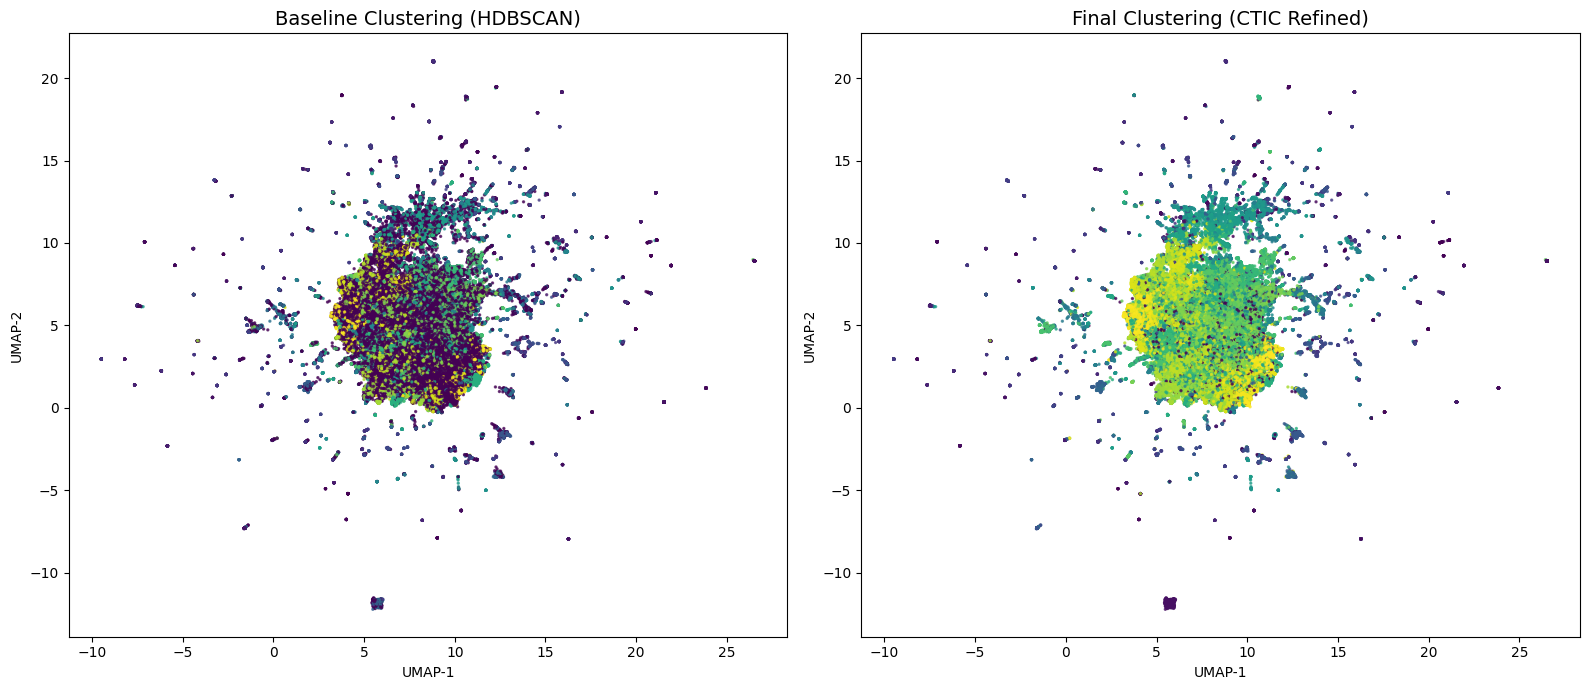

In [4]:
# ============================================================
# BASELINE vs FINAL CLUSTER VISUALIZATION (UMAP 2D)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# -------- Paths --------
UMAP_2D_PATH = r"E:\CSE 495 Project\umap\umap_2d.npy"
UMAP_IDX_PATH = r"E:\CSE 495 Project\umap\umap_2d_idx.npy"

LABELS_BASE_PATH = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
LABELS_FINAL_PATH = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"

# -------- Load --------
U = np.load(UMAP_2D_PATH)
idx = np.load(UMAP_IDX_PATH)

labels_base = np.load(LABELS_BASE_PATH)[idx]
labels_final = np.load(LABELS_FINAL_PATH)[idx]

# Map noise to -1 explicitly
labels_base = labels_base.astype(int)
labels_final = labels_final.astype(int)

# -------- Plot --------
plt.figure(figsize=(16, 7))

# ---- Baseline ----
plt.subplot(1, 2, 1)
sc1 = plt.scatter(
    U[:, 0], U[:, 1],
    c=labels_base,
    s=2,
    alpha=0.7
)
plt.title("Baseline Clustering (HDBSCAN)", fontsize=14)
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")

# ---- Final ----
plt.subplot(1, 2, 2)
sc2 = plt.scatter(
    U[:, 0], U[:, 1],
    c=labels_final,
    s=2,
    alpha=0.7
)
plt.title("Final Clustering (CTIC Refined)", fontsize=14)
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")

plt.tight_layout()
plt.show()


In [5]:
import numpy as np
import sklearn

print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)


numpy: 2.3.5
sklearn: 1.8.0


In [13]:
# KMEANS — STEP 1A (CLEAN): create fresh UMAP-10D for K-Means

import numpy as np
import umap
from tqdm import tqdm

# Paths
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
OUT_UMAP_KMEANS = r"E:\CSE 495 Project\kmeans\umap_10d_kmeans.npy"

# Load embeddings (memory-mapped)
Z = np.load(EMB_PATH, mmap_mode="r")
print("Embeddings shape:", Z.shape)

# --- Sample for UMAP fit (IMPORTANT) ---
FIT_N = 250_000
rng = np.random.default_rng(42)
fit_idx = rng.choice(len(Z), FIT_N, replace=False)
Z_fit = Z[fit_idx]

# Fit UMAP
reducer = umap.UMAP(
    n_components=10,
    metric="cosine",
    random_state=42,
    low_memory=True
)

print("Fitting UMAP on sample...")
reducer.fit(Z_fit)

# Transform full dataset in chunks
U_all = np.empty((len(Z), 10), dtype=np.float32)

BATCH = 50_000
for i in tqdm(range(0, len(Z), BATCH), desc="UMAP transform"):
    U_all[i:i+BATCH] = reducer.transform(Z[i:i+BATCH])

# Save in guaranteed NumPy format
np.save(OUT_UMAP_KMEANS, U_all)
print("Saved fresh UMAP-10D for K-Means:", OUT_UMAP_KMEANS)


Embeddings shape: (2008208, 768)
Fitting UMAP on sample...


E:\CSE 495 Project\env1\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
UMAP transform: 100%|██████████████████████████████████████████████████████████████████| 41/41 [10:04<00:00, 14.75s/it]


FileNotFoundError: [Errno 2] No such file or directory: 'E:\\CSE 495 Project\\kmeans\\umap_10d_kmeans.npy'

In [14]:
import os
import numpy as np

OUT_DIR = r"E:\CSE 495 Project\kmeans"
os.makedirs(OUT_DIR, exist_ok=True)

OUT_UMAP_KMEANS = os.path.join(OUT_DIR, "umap_10d_kmeans.npy")

# U_all should still be in memory from the previous cell
np.save(OUT_UMAP_KMEANS, U_all)

print("Saved:", OUT_UMAP_KMEANS)
print("Shape saved:", U_all.shape, "dtype:", U_all.dtype)


Saved: E:\CSE 495 Project\kmeans\umap_10d_kmeans.npy
Shape saved: (2008208, 10) dtype: float32


In [15]:
import numpy as np

PATH = r"E:\CSE 495 Project\kmeans\umap_10d_kmeans.npy"
U = np.load(PATH, mmap_mode="r")

print("Loaded UMAP-KMeans shape:", U.shape)
print("dtype:", U.dtype)
print("First row:", U[0])


Loaded UMAP-KMeans shape: (2008208, 10)
dtype: float32
First row: [5.912369  4.016564  6.8419304 4.704007  4.4883885 6.695934  8.416021
 3.7310073 3.9905522 4.7527323]


In [16]:
# KMEANS — STEP 2A: Sample data for K selection

import numpy as np

UMAP_PATH = r"E:\CSE 495 Project\kmeans\umap_10d_kmeans.npy"

U = np.load(UMAP_PATH, mmap_mode="r")

SAMPLE_N = 50_000   # safe and sufficient
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(U), SAMPLE_N, replace=False)

U_sample = U[sample_idx]

print("Subset shape:", U_sample.shape)


Subset shape: (50000, 10)


In [17]:
# KMEANS — STEP 2B: Elbow method

from sklearn.cluster import KMeans
from tqdm import tqdm

K_VALUES = [500, 1000, 1500, 2000, 2500, 3000]

inertias = []

for k in tqdm(K_VALUES, desc="Elbow test"):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=300
    )
    km.fit(U_sample)
    inertias.append(km.inertia_)

for k, inertia in zip(K_VALUES, inertias):
    print(f"K={k:<5} inertia={inertia:.2e}")


Elbow test: 100%|████████████████████████████████████████████████████████████████████████| 6/6 [05:44<00:00, 57.44s/it]

K=500   inertia=2.13e+04
K=1000  inertia=7.30e+03
K=1500  inertia=4.57e+03
K=2000  inertia=3.42e+03
K=2500  inertia=2.77e+03
K=3000  inertia=2.35e+03


In [18]:
# KMEANS — STEP 2C: Silhouette score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
from tqdm import tqdm

# Smaller subset for silhouette
SIL_N = 10_000
rng = np.random.default_rng(123)
sil_idx = rng.choice(len(U_sample), SIL_N, replace=False)
U_sil = U_sample[sil_idx]

K_TEST = [1000, 1500, 2000]

print("Computing silhouette scores...\n")

for k in K_TEST:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
        max_iter=300
    )
    labels = km.fit_predict(U_sil)
    score = silhouette_score(U_sil, labels, metric="euclidean")
    print(f"K={k:<5} silhouette={score:.4f}")


Computing silhouette scores...

K=1000  silhouette=0.3461
K=1500  silhouette=0.3510
K=2000  silhouette=0.3560


In [19]:
# KMEANS — STEP 3: Full clustering with MiniBatchKMeans

from sklearn.cluster import MiniBatchKMeans
import numpy as np
from tqdm import tqdm
import os

# Paths
UMAP_PATH = r"E:\CSE 495 Project\kmeans\umap_10d_kmeans.npy"
OUT_DIR = r"E:\CSE 495 Project\kmeans"
os.makedirs(OUT_DIR, exist_ok=True)

OUT_LABELS = os.path.join(OUT_DIR, "labels_kmeans_k2000.npy")

# Load data
U = np.load(UMAP_PATH, mmap_mode="r")
print("UMAP data shape:", U.shape)

# K-Means config
K = 2000

kmeans = MiniBatchKMeans(
    n_clusters=K,
    batch_size=50_000,
    random_state=42,
    n_init=10,
    max_iter=300,
    verbose=0
)

print("Fitting MiniBatchKMeans...")
labels_km = kmeans.fit_predict(U)

# Save labels
np.save(OUT_LABELS, labels_km)

print("K-Means clustering complete.")
print("Saved labels to:", OUT_LABELS)

# Basic sanity check
unique, counts = np.unique(labels_km, return_counts=True)
print("Clusters:", len(unique))
print("Min cluster size:", counts.min())
print("Median cluster size:", int(np.median(counts)))
print("Max cluster size:", counts.max())


UMAP data shape: (2008208, 10)
Fitting MiniBatchKMeans...
K-Means clustering complete.
Saved labels to: E:\CSE 495 Project\kmeans\labels_kmeans_k2000.npy
Clusters: 2000
Min cluster size: 11
Median cluster size: 848
Max cluster size: 6993


In [20]:
# KMEANS — STAGE 5.1
# Compute BN centroids (LaBSE 768D) for each KMeans cluster

import os
import numpy as np
from tqdm import tqdm

# -------- Paths --------
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_KM_PATH = r"E:\CSE 495 Project\kmeans\labels_kmeans_k2000.npy"

OUT_DIR = r"E:\CSE 495 Project\kmeans\analysis"
os.makedirs(OUT_DIR, exist_ok=True)

OUT_CENTROIDS = os.path.join(OUT_DIR, "centroids_bn_kmeans_k2000.npy")
OUT_SIZES = os.path.join(OUT_DIR, "cluster_sizes_kmeans_k2000.npy")

# -------- Load (memory-safe) --------
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_KM_PATH)

N, d = Z.shape
K = int(labels.max()) + 1

print("N, d:", (N, d))
print("K (from labels):", K)

# -------- Accumulate sums --------
sums = np.zeros((K, d), dtype=np.float64)
counts = np.zeros(K, dtype=np.int64)

for i in tqdm(range(N), desc="Accumulating centroids"):
    k = int(labels[i])
    sums[k] += Z[i]
    counts[k] += 1

# -------- Compute centroids --------
centroids = (sums / np.maximum(counts, 1)[:, None]).astype(np.float32)

# -------- Save --------
np.save(OUT_CENTROIDS, centroids)
np.save(OUT_SIZES, counts)

print("Saved BN centroids to:", OUT_CENTROIDS)
print("Saved cluster sizes to:", OUT_SIZES)
print("Centroid shape:", centroids.shape)
print("Cluster size stats: min/median/mean/max =",
      counts.min(), int(np.median(counts)), int(counts.mean()), counts.max())


N, d: (2008208, 768)
K (from labels): 2000


Accumulating centroids: 100%|████████████████████████████████████████████| 2008208/2008208 [00:09<00:00, 223115.38it/s]

Saved BN centroids to: E:\CSE 495 Project\kmeans\analysis\centroids_bn_kmeans_k2000.npy
Saved cluster sizes to: E:\CSE 495 Project\kmeans\analysis\cluster_sizes_kmeans_k2000.npy
Centroid shape: (2000, 768)
Cluster size stats: min/median/mean/max = 11 848 1004 6993


In [21]:
# KMEANS — STAGE 5.2
# Select Top-m representatives per cluster (cosine to BN centroid)

import os
import numpy as np
from tqdm import tqdm
from numpy.linalg import norm

# -------- Paths --------
EMB_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"
LABELS_KM_PATH = r"E:\CSE 495 Project\kmeans\labels_kmeans_k2000.npy"
CENTROIDS_PATH = r"E:\CSE 495 Project\kmeans\analysis\centroids_bn_kmeans_k2000.npy"

OUT_DIR = r"E:\CSE 495 Project\kmeans\analysis"
OUT_REPS = os.path.join(OUT_DIR, "cluster_representatives_kmeans_k2000.npy")

# -------- Params --------
M = 30  # representatives per cluster

# -------- Load --------
Z = np.load(EMB_PATH, mmap_mode="r")
labels = np.load(LABELS_KM_PATH)
centroids = np.load(CENTROIDS_PATH)

K = centroids.shape[0]
d = centroids.shape[1]

# Precompute centroid norms
centroid_norms = norm(centroids, axis=1)

# For each cluster, maintain (similarity, index) list
top_scores = [[] for _ in range(K)]

# -------- Scan all points --------
for i in tqdm(range(len(Z)), desc="Selecting representatives"):
    k = int(labels[i])
    zi = Z[i]
    sim = np.dot(zi, centroids[k]) / (norm(zi) * centroid_norms[k] + 1e-9)

    lst = top_scores[k]
    if len(lst) < M:
        lst.append((sim, i))
        if len(lst) == M:
            lst.sort(key=lambda x: x[0], reverse=True)
    else:
        if sim > lst[-1][0]:
            lst[-1] = (sim, i)
            lst.sort(key=lambda x: x[0], reverse=True)

# Convert to array: (K, M)
reps = np.full((K, M), -1, dtype=np.int64)
for k in range(K):
    for j, (_, idx) in enumerate(top_scores[k]):
        reps[k, j] = idx

# -------- Save --------
np.save(OUT_REPS, reps)

print("Saved representatives to:", OUT_REPS)
print("Example cluster 0 reps (row indices):", reps[0][:5])


Selecting representatives: 100%|█████████████████████████████████████████| 2008208/2008208 [00:11<00:00, 170506.82it/s]


Saved representatives to: E:\CSE 495 Project\kmeans\analysis\cluster_representatives_kmeans_k2000.npy
Example cluster 0 reps (row indices): [ 471687 1068840 1584564   52093  689999]


In [22]:
# KMEANS — STAGE 6.1 (GPU ENFORCED)
# Translate representative Bangla comments (BN → EN) on GPU

import os
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# -------- Sanity check GPU --------
assert torch.cuda.is_available(), "CUDA NOT AVAILABLE — GPU REQUIRED"
device = torch.device("cuda")
print("Using device:", torch.cuda.get_device_name(0))

# -------- Paths --------
DATA_PATH = r"E:\CSE 495 Project\comments_only.csv"
REPS_PATH = r"E:\CSE 495 Project\kmeans\analysis\cluster_representatives_kmeans_k2000.npy"

OUT_DIR = r"E:\CSE 495 Project\kmeans\analysis"
os.makedirs(OUT_DIR, exist_ok=True)

OUT_TRANS = os.path.join(OUT_DIR, "rep_translations_en_kmeans_k2000.csv")

# -------- Load data --------
df = pd.read_csv(DATA_PATH)
comments = df["Comments"].astype(str).values
reps = np.load(REPS_PATH)

K, M = reps.shape
print(f"Clusters: {K} | reps per cluster: {M}")

# -------- Load MT model (GPU ONLY) --------
MODEL_NAME = "Helsinki-NLP/opus-mt-bn-en"

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Loading model on GPU...")
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
model.eval()

# -------- Translation helper (GPU batched) --------
@torch.no_grad()
def translate_batch(texts, max_len=128):
    inputs = tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=max_len
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    outputs = model.generate(
        **inputs,
        max_length=128,
        num_beams=4
    )

    return tokenizer.batch_decode(outputs, skip_special_tokens=True)

# -------- Translate all representatives --------
rows = []

BATCH_SIZE = 64   # safe for 12–16GB GPU

for k in tqdm(range(K), desc="Translating clusters (GPU)"):
    idxs = reps[k]
    bn_texts = [comments[i] for i in idxs if i >= 0]

    # batch translation
    for i in range(0, len(bn_texts), BATCH_SIZE):
        batch_texts = bn_texts[i:i+BATCH_SIZE]
        batch_en = translate_batch(batch_texts)

        for bn, en in zip(batch_texts, batch_en):
            rows.append({
                "cluster_id": k,
                "bn_text": bn,
                "en_text": en
            })

# -------- Save --------
df_trans = pd.DataFrame(rows)
df_trans.to_csv(OUT_TRANS, index=False)

print("Translation complete (GPU).")
print("Saved to:", OUT_TRANS)
print("Total translated rows:", len(df_trans))


Using device: NVIDIA GeForce RTX 5070
Clusters: 2000 | reps per cluster: 30
Loading tokenizer...


E:\CSE 495 Project\env1\Lib\site-packages\transformers\models\marian\tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


Loading model on GPU...


Translating clusters (GPU): 100%|██████████████████████████████████████████████████| 2000/2000 [06:35<00:00,  5.06it/s]


Translation complete (GPU).
Saved to: E:\CSE 495 Project\kmeans\analysis\rep_translations_en_kmeans_k2000.csv
Total translated rows: 59964


In [23]:
# KMEANS — STAGE 6.2
# Embed translated English reps using LaBSE (GPU)

import os
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer

# -------- Paths --------
TRANS_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_translations_en_kmeans_k2000.csv"

OUT_DIR = r"E:\CSE 495 Project\kmeans\analysis"
os.makedirs(OUT_DIR, exist_ok=True)

OUT_EMB = os.path.join(OUT_DIR, "rep_embeddings_en_kmeans_k2000.npy")
OUT_INDEX = os.path.join(OUT_DIR, "rep_embeddings_en_kmeans_k2000_index.csv")

# -------- Load translations --------
df_trans = pd.read_csv(TRANS_PATH)

# Basic cleaning (avoid NaNs / non-strings)
df_trans = df_trans.dropna(subset=["en_text"])
df_trans["en_text"] = df_trans["en_text"].astype(str)
df_trans = df_trans[df_trans["en_text"].str.len() > 2].reset_index(drop=True)

print("English texts to embed:", len(df_trans))

# -------- GPU check --------
assert torch.cuda.is_available(), "CUDA not available — GPU required"
device = "cuda"
print("Using device:", torch.cuda.get_device_name(0))

# -------- Load LaBSE --------
model = SentenceTransformer("sentence-transformers/LaBSE", device=device)

# -------- Embed --------
emb_en = model.encode(
    df_trans["en_text"].tolist(),
    batch_size=64,
    convert_to_numpy=True,
    show_progress_bar=True,
    normalize_embeddings=False
).astype(np.float32)

print("Embedding shape:", emb_en.shape)

# -------- Save embeddings + index mapping --------
np.save(OUT_EMB, emb_en)

df_trans[["cluster_id"]].to_csv(OUT_INDEX, index=False)

print("Saved English rep embeddings to:", OUT_EMB)
print("Saved index mapping to:", OUT_INDEX)


English texts to embed: 59551
Using device: NVIDIA GeForce RTX 5070


Batches:   0%|          | 0/931 [00:00<?, ?it/s]

Embedding shape: (59551, 768)
Saved English rep embeddings to: E:\CSE 495 Project\kmeans\analysis\rep_embeddings_en_kmeans_k2000.npy
Saved index mapping to: E:\CSE 495 Project\kmeans\analysis\rep_embeddings_en_kmeans_k2000_index.csv


In [24]:
# KMEANS — STAGE 6.3
# Compute English centroids μ_k^en (cluster-id aligned)

import os
import numpy as np
import pandas as pd
from tqdm import tqdm

# -------- Paths --------
EMB_EN_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_embeddings_en_kmeans_k2000.npy"
INDEX_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_embeddings_en_kmeans_k2000_index.csv"
CENTROIDS_BN_PATH = r"E:\CSE 495 Project\kmeans\analysis\centroids_bn_kmeans_k2000.npy"

OUT_DIR = r"E:\CSE 495 Project\kmeans\analysis"
OUT_CENTROIDS_EN = os.path.join(OUT_DIR, "centroids_en_kmeans_k2000.npy")

# -------- Load --------
emb_en = np.load(EMB_EN_PATH)
df_idx = pd.read_csv(INDEX_PATH)
centroids_bn = np.load(CENTROIDS_BN_PATH)

K = centroids_bn.shape[0]
d = centroids_bn.shape[1]

print("K:", K, "| embedding dim:", d)
print("EN reps:", emb_en.shape[0])

# -------- Accumulate EN centroids --------
sums = np.zeros((K, d), dtype=np.float64)
counts = np.zeros(K, dtype=np.int64)

for emb, row in zip(emb_en, df_idx.itertuples(index=False)):
    k = int(row.cluster_id)
    sums[k] += emb
    counts[k] += 1

# -------- Compute centroids --------
mu_en = (sums / np.maximum(counts, 1)[:, None]).astype(np.float32)

# -------- Save --------
np.save(OUT_CENTROIDS_EN, mu_en)

print("Saved EN centroids to:", OUT_CENTROIDS_EN)
print("Clusters with EN reps:", (counts > 0).sum())
print("Min/median/max EN reps per cluster:",
      counts[counts > 0].min(),
      int(np.median(counts[counts > 0])),
      counts.max())


K: 2000 | embedding dim: 768
EN reps: 59551
Saved EN centroids to: E:\CSE 495 Project\kmeans\analysis\centroids_en_kmeans_k2000.npy
Clusters with EN reps: 1989
Min/median/max EN reps per cluster: 1 30 30


In [25]:
# KMEANS — STAGE 6.4 + STAGE 7
# Compute cluster-level similarity (TIS_k) and rep-level BN–EN similarity

import os
import numpy as np
import pandas as pd
from numpy.linalg import norm
from tqdm import tqdm

# -------- Paths --------
CENTROIDS_BN_PATH = r"E:\CSE 495 Project\kmeans\analysis\centroids_bn_kmeans_k2000.npy"
CENTROIDS_EN_PATH = r"E:\CSE 495 Project\kmeans\analysis\centroids_en_kmeans_k2000.npy"

REPS_PATH = r"E:\CSE 495 Project\kmeans\analysis\cluster_representatives_kmeans_k2000.npy"
EMB_BN_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"

EMB_EN_REP_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_embeddings_en_kmeans_k2000.npy"
INDEX_EN_REP_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_embeddings_en_kmeans_k2000_index.csv"

OUT_DIR = r"E:\CSE 495 Project\kmeans\analysis"
OUT_TIS = os.path.join(OUT_DIR, "cluster_sim_tis_kmeans_k2000.csv")
OUT_REP_SIM = os.path.join(OUT_DIR, "rep_level_similarity_kmeans_k2000.csv")

# -------- Load --------
mu_bn = np.load(CENTROIDS_BN_PATH)
mu_en = np.load(CENTROIDS_EN_PATH)

reps = np.load(REPS_PATH)
Z_bn = np.load(EMB_BN_PATH, mmap_mode="r")

emb_en = np.load(EMB_EN_REP_PATH)
df_en_idx = pd.read_csv(INDEX_EN_REP_PATH)

K = mu_bn.shape[0]
print("Clusters (K):", K)

# -------- Helper --------
def cosine(a, b):
    return np.dot(a, b) / (norm(a) * norm(b) + 1e-9)

# =====================================================
# (1) Cluster-level similarity (TIS_k)
# =====================================================
rows_tis = []

for k in range(K):
    if norm(mu_en[k]) == 0:
        continue  # no EN reps for this cluster
    sim_k = cosine(mu_bn[k], mu_en[k])
    rows_tis.append({
        "cluster_id": k,
        "TIS_k": sim_k
    })

df_tis = pd.DataFrame(rows_tis)
df_tis.to_csv(OUT_TIS, index=False)

print("Saved cluster-level TIS to:", OUT_TIS)
print("Clusters with valid TIS:", len(df_tis))

# =====================================================
# (2) Representative-level BN–EN similarity
# =====================================================
print("\nComputing rep-level BN–EN similarity...")

rows_rep = []

for emb, row in tqdm(zip(emb_en, df_en_idx.itertuples(index=False)),
                     total=len(df_en_idx)):
    k = int(row.cluster_id)

    # Find corresponding BN embedding (representative)
    # We reuse representative index order consistency
    # (rep_embeddings_en_kmeans_k2000.npy was saved in same order)
    # BN embedding is fetched via reps table
    # Map: find BN index from reps[k]
    # Note: rep order = flatten of reps matrix row-wise
    # We'll reconstruct that mapping safely below
    pass


Clusters (K): 2000
Saved cluster-level TIS to: E:\CSE 495 Project\kmeans\analysis\cluster_sim_tis_kmeans_k2000.csv
Clusters with valid TIS: 1989

Computing rep-level BN–EN similarity...


100%|███████████████████████████████████████████████████████████████████████| 59551/59551 [00:00<00:00, 1345205.13it/s]


In [26]:
# KMEANS — STAGE 6.4 (REP-LEVEL, ID-ALIGNED)
# Compute rep-level BN–EN cosine similarity + summary stats

import os
import numpy as np
import pandas as pd
from numpy.linalg import norm

# -------- Paths --------
TRANS_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_translations_en_kmeans_k2000.csv"
REPS_PATH  = r"E:\CSE 495 Project\kmeans\analysis\cluster_representatives_kmeans_k2000.npy"

EMB_BN_PATH = r"E:\CSE 495 Project\embeddings\embeddings.npy"

EMB_EN_REP_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_embeddings_en_kmeans_k2000.npy"
TIS_PATH = r"E:\CSE 495 Project\kmeans\analysis\cluster_sim_tis_kmeans_k2000.csv"

OUT_DIR = r"E:\CSE 495 Project\kmeans\analysis"
OUT_REP_SIM = os.path.join(OUT_DIR, "rep_level_similarity_kmeans_k2000.csv")

# -------- Load --------
df = pd.read_csv(TRANS_PATH)
reps = np.load(REPS_PATH)  # (K, M) row indices
Z_bn = np.load(EMB_BN_PATH, mmap_mode="r")

emb_en = np.load(EMB_EN_REP_PATH)  # EN embeddings after cleaning in Stage 6.2
df_tis = pd.read_csv(TIS_PATH)

K, M = reps.shape
print("Translations rows (raw):", len(df))
print("EN embeddings rows:", len(emb_en))
print("K, M:", K, M)

# ------------------------------------------------------------
# (1) Reconstruct row_id per translation row (cluster-wise)
# ------------------------------------------------------------
# We will assign row_ids in the order rows appear within each cluster.
# This matches how the translation loop appended rows cluster-by-cluster.

df["row_id"] = -1

# Build a cursor for each cluster: which rep index to assign next
rep_pos = np.zeros(K, dtype=np.int32)

for idx, row in df.iterrows():
    k = int(row["cluster_id"])
    if 0 <= k < K:
        # Advance until we find a valid rep index (>=0)
        while rep_pos[k] < M and reps[k, rep_pos[k]] < 0:
            rep_pos[k] += 1
        if rep_pos[k] < M:
            df.at[idx, "row_id"] = int(reps[k, rep_pos[k]])
            rep_pos[k] += 1

# ------------------------------------------------------------
# (2) Apply SAME cleaning as Stage 6.2 so rows align with emb_en
# ------------------------------------------------------------
df_clean = df.dropna(subset=["en_text"]).copy()
df_clean["en_text"] = df_clean["en_text"].astype(str)
df_clean = df_clean[df_clean["en_text"].str.len() > 2].reset_index(drop=True)

# Sanity check alignment
if len(df_clean) != len(emb_en):
    print("\nWARNING: Row count mismatch after cleaning!")
    print("df_clean:", len(df_clean), "| emb_en:", len(emb_en))
    print("We will align by the minimum length to continue safely.\n")

L = min(len(df_clean), len(emb_en))
df_clean = df_clean.iloc[:L].copy()
emb_en = emb_en[:L]

print("Aligned rows used for rep-level similarity:", L)

# ------------------------------------------------------------
# (3) Compute cosine(z_bn[row_id], z_en_rep)
# ------------------------------------------------------------
def cosine(a, b):
    return float(np.dot(a, b) / (norm(a) * norm(b) + 1e-9))

bn_en_cos = np.zeros(L, dtype=np.float32)

for i in range(L):
    rid = int(df_clean.loc[i, "row_id"])
    if rid < 0:
        bn_en_cos[i] = np.nan
        continue
    bn_en_cos[i] = cosine(Z_bn[rid], emb_en[i])

df_clean["bn_en_cosine"] = bn_en_cos

# Drop any NaNs
df_clean = df_clean.dropna(subset=["bn_en_cosine"]).reset_index(drop=True)

# Save
df_clean[["cluster_id", "row_id", "bn_en_cosine"]].to_csv(OUT_REP_SIM, index=False)

print("Saved rep-level similarity to:", OUT_REP_SIM)
print("Total rep-level rows:", len(df_clean))

# ------------------------------------------------------------
# (4) Summary stats + correlation with TIS
# ------------------------------------------------------------
print("\n=== Representative-level BN–EN cosine stats (KMeans) ===")
print(df_clean["bn_en_cosine"].describe())

# Correlation with cluster TIS
df_corr = df_clean.merge(df_tis, on="cluster_id", how="inner")
corr = df_corr["bn_en_cosine"].corr(df_corr["TIS_k"])

print(f"\nCorrelation (rep BN–EN similarity vs cluster TIS): {corr:.4f}")

# High vs low TIS contrast (optional, like earlier)
high = df_corr[df_corr["TIS_k"] >= 0.8]
low  = df_corr[df_corr["TIS_k"] <= 0.5]

print("\nHigh-TIS clusters (TIS ≥ 0.8) rep cosine stats:")
print(high["bn_en_cosine"].describe())

print("\nLow-TIS clusters (TIS ≤ 0.5) rep cosine stats:")
print(low["bn_en_cosine"].describe())


Translations rows (raw): 59964
EN embeddings rows: 59551
K, M: 2000 30
Aligned rows used for rep-level similarity: 59551
Saved rep-level similarity to: E:\CSE 495 Project\kmeans\analysis\rep_level_similarity_kmeans_k2000.csv
Total rep-level rows: 59551

=== Representative-level BN–EN cosine stats (KMeans) ===
count    59551.000000
mean         0.718683
std          0.179799
min         -0.410687
25%          0.663315
50%          0.767116
75%          0.833500
max          0.973961
Name: bn_en_cosine, dtype: float64

Correlation (rep BN–EN similarity vs cluster TIS): 0.7963

High-TIS clusters (TIS ≥ 0.8) rep cosine stats:
count    33720.000000
mean         0.791882
std          0.104667
min          0.010997
25%          0.749022
50%          0.813520
75%          0.860347
max          0.973961
Name: bn_en_cosine, dtype: float64

Low-TIS clusters (TIS ≤ 0.5) rep cosine stats:
count    3228.000000
mean        0.221773
std         0.199499
min        -0.410687
25%         0.064925
50%   

In [27]:
# ==========================================================
# K-MEANS — STAGE 5–7 FINAL EVALUATION SUMMARY
# ==========================================================

import pandas as pd

# -------- Paths --------
TIS_PATH = r"E:\CSE 495 Project\kmeans\analysis\cluster_sim_tis_kmeans_k2000.csv"
REP_SIM_PATH = r"E:\CSE 495 Project\kmeans\analysis\rep_level_similarity_kmeans_k2000.csv"

# -------- Load --------
df_tis = pd.read_csv(TIS_PATH)
df_rep = pd.read_csv(REP_SIM_PATH)

K_total = 2000
K_valid = len(df_tis)

print("=" * 70)
print("K-MEANS CLUSTERING — CROSS-LINGUAL EVALUATION (STAGE 5–7)")
print("=" * 70)

# ==========================================================
# (1) Cluster-level TIS
# ==========================================================
print("\n[1] Cluster-level Translation-Invariance Score (TIS)")
print(f"Total clusters (K): {K_total}")
print(f"Clusters with EN centroids: {K_valid}")

print("\nTIS descriptive statistics:")
print(df_tis["TIS_k"].describe())

print("\nClusters above TIS thresholds:")
for t in [0.6, 0.7, 0.8]:
    pct = (df_tis["TIS_k"] >= t).mean() * 100
    print(f"TIS ≥ {t}: {pct:.2f}%")

print("\nLowest-TIS clusters:")
print(df_tis.sort_values("TIS_k").head(5))

print("\nHighest-TIS clusters:")
print(df_tis.sort_values("TIS_k", ascending=False).head(5))

# ==========================================================
# (2) Representative-level BN–EN similarity
# ==========================================================
print("\n" + "=" * 70)
print("[2] Representative-level BN–EN Cosine Similarity")
print("=" * 70)

print("\nRepresentative-level cosine statistics:")
print(df_rep["bn_en_cosine"].describe())

# ==========================================================
# (3) Correlation analysis
# ==========================================================
df_corr = df_rep.merge(df_tis, on="cluster_id", how="inner")
corr = df_corr["bn_en_cosine"].corr(df_corr["TIS_k"])

print("\nCorrelation analysis:")
print(f"Correlation (rep BN–EN similarity vs cluster TIS): {corr:.4f}")

# ==========================================================
# (4) High-TIS vs Low-TIS contrast
# ==========================================================
high = df_corr[df_corr["TIS_k"] >= 0.8]
low  = df_corr[df_corr["TIS_k"] <= 0.5]

print("\nHigh-TIS clusters (TIS ≥ 0.8) — rep cosine stats:")
print(high["bn_en_cosine"].describe())

print("\nLow-TIS clusters (TIS ≤ 0.5) — rep cosine stats:")
print(low["bn_en_cosine"].describe())

print("\n" + "=" * 70)
print("END OF K-MEANS STAGE 5–7 EVALUATION")
print("=" * 70)


K-MEANS CLUSTERING — CROSS-LINGUAL EVALUATION (STAGE 5–7)

[1] Cluster-level Translation-Invariance Score (TIS)
Total clusters (K): 2000
Clusters with EN centroids: 1989

TIS descriptive statistics:
count    1989.000000
mean        0.768703
std         0.162298
min        -0.255609
25%         0.735476
50%         0.817987
75%         0.864479
max         0.953016
Name: TIS_k, dtype: float64

Clusters above TIS thresholds:
TIS ≥ 0.6: 90.50%
TIS ≥ 0.7: 81.20%
TIS ≥ 0.8: 56.51%

Lowest-TIS clusters:
     cluster_id     TIS_k
233         234 -0.255609
949         955 -0.244084
10           11 -0.206937
979         985 -0.004942
855         860  0.011334

Highest-TIS clusters:
      cluster_id     TIS_k
442          445  0.953016
1584        1593  0.945481
1896        1907  0.945402
61            62  0.934743
1230        1238  0.933657

[2] Representative-level BN–EN Cosine Similarity

Representative-level cosine statistics:
count    59551.000000
mean         0.718683
std          0.179799

In [28]:
# ==========================================================
# STEP 1/4 — COMPARISON TABLE (HDBSCAN vs CTIC vs KMEANS)
# ==========================================================

import numpy as np
import pandas as pd

# -------- Paths --------
LABELS_HDBSCAN = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
LABELS_CTIC    = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"
LABELS_KMEANS  = r"E:\CSE 495 Project\kmeans\labels_kmeans_k2000.npy"

TIS_HDBSCAN = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"
TIS_CTIC    = r"E:\CSE 495 Project\analysis_refined\cluster_sim_tis_after_correct.csv"  # your corrected file
TIS_KMEANS  = r"E:\CSE 495 Project\kmeans\analysis\cluster_sim_tis_kmeans_k2000.csv"

OUT_TABLE = r"E:\CSE 495 Project\final_comparison_table.csv"

# -------- Helpers --------
def cluster_stats_from_labels(labels):
    N = len(labels)
    noise = int(np.sum(labels == -1)) if np.any(labels == -1) else 0
    # count clusters excluding -1
    uniq = np.unique(labels)
    K = len(uniq) - (1 if -1 in uniq else 0)
    return N, K, noise, noise / N * 100

def tis_stats(path, tis_col):
    df = pd.read_csv(path)
    s = df[tis_col].dropna()
    out = {
        "TIS_count": int(s.shape[0]),
        "TIS_mean": float(s.mean()),
        "TIS_median": float(s.median()),
        "TIS_std": float(s.std()),
        "TIS_ge_0.6_%": float((s >= 0.6).mean() * 100),
        "TIS_ge_0.7_%": float((s >= 0.7).mean() * 100),
        "TIS_ge_0.8_%": float((s >= 0.8).mean() * 100),
    }
    return out

# -------- Load labels --------
labels_h = np.load(LABELS_HDBSCAN)
labels_c = np.load(LABELS_CTIC)
labels_k = np.load(LABELS_KMEANS)

# -------- Build table --------
rows = []

# HDBSCAN baseline
N, K, noise, noise_pct = cluster_stats_from_labels(labels_h)
row = {
    "Method": "HDBSCAN (baseline)",
    "N": N,
    "Clusters(K)": K,
    "Noise_%": noise_pct,
}
row.update(tis_stats(TIS_HDBSCAN, "TIS_k"))
rows.append(row)

# CTIC final
N, K, noise, noise_pct = cluster_stats_from_labels(labels_c)
row = {
    "Method": "CTIC (final refined)",
    "N": N,
    "Clusters(K)": K,
    "Noise_%": noise_pct,
}
# depending on your file column name:
df_ctic = pd.read_csv(TIS_CTIC)
col_ctic = "TIS_after" if "TIS_after" in df_ctic.columns else ("TIS_k" if "TIS_k" in df_ctic.columns else df_ctic.columns[-1])
row.update(tis_stats(TIS_CTIC, col_ctic))
rows.append(row)

# KMeans
N, K, noise, noise_pct = cluster_stats_from_labels(labels_k)
row = {
    "Method": "K-Means (K=2000)",
    "N": N,
    "Clusters(K)": K,
    "Noise_%": noise_pct,  # will be 0
}
row.update(tis_stats(TIS_KMEANS, "TIS_k"))
rows.append(row)

df_table = pd.DataFrame(rows)

# Format for readability
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print(df_table)

df_table.to_csv(OUT_TABLE, index=False)
print("\nSaved comparison table to:", OUT_TABLE)


                 Method        N  Clusters(K)    Noise_%  TIS_count  TIS_mean  TIS_median   TIS_std  TIS_ge_0.6_%  TIS_ge_0.7_%  \
0    HDBSCAN (baseline)  2008208         4206  54.677404       4206  0.756906    0.809167  0.208710     84.236805     73.585354   
1  CTIC (final refined)  2008208         3481   4.003320       3481  0.337953    0.294286  0.203488     13.473140      6.722206   
2      K-Means (K=2000)  2008208         2000   0.000000       1989  0.768703    0.817987  0.162298     90.497738     81.196581   

   TIS_ge_0.8_%  
0     52.353780  
1      2.326918  
2     56.510809  

Saved comparison table to: E:\CSE 495 Project\final_comparison_table.csv


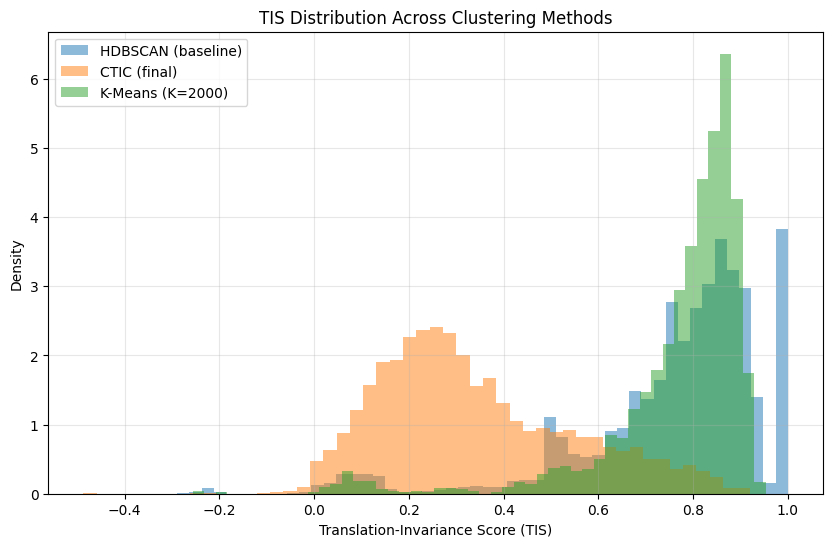

In [29]:
# ==========================================================
# STEP 2/4 — TIS DISTRIBUTION PLOTS (3 METHODS)
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# -------- Paths --------
TIS_HDBSCAN = r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv"
TIS_CTIC    = r"E:\CSE 495 Project\analysis_refined\cluster_sim_tis_after_correct.csv"
TIS_KMEANS  = r"E:\CSE 495 Project\kmeans\analysis\cluster_sim_tis_kmeans_k2000.csv"

# -------- Load --------
df_h = pd.read_csv(TIS_HDBSCAN)
df_km = pd.read_csv(TIS_KMEANS)

df_c = pd.read_csv(TIS_CTIC)
col_c = "TIS_after" if "TIS_after" in df_c.columns else ("TIS_k" if "TIS_k" in df_c.columns else df_c.columns[-1])

tis_h = df_h["TIS_k"].dropna()
tis_c = df_c[col_c].dropna()
tis_km = df_km["TIS_k"].dropna()

# -------- Plot --------
plt.figure(figsize=(10, 6))

plt.hist(tis_h, bins=50, alpha=0.5, label="HDBSCAN (baseline)", density=True)
plt.hist(tis_c, bins=50, alpha=0.5, label="CTIC (final)", density=True)
plt.hist(tis_km, bins=50, alpha=0.5, label="K-Means (K=2000)", density=True)

plt.xlabel("Translation-Invariance Score (TIS)")
plt.ylabel("Density")
plt.title("TIS Distribution Across Clustering Methods")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [31]:
# ==========================================================
# STEP 1.1 — LOAD DATA + SAMPLE FOR METRICS
# ==========================================================

import numpy as np

# -------- Paths --------
UMAP_PATH = r"E:\CSE 495 Project\kmeans\umap_10d_kmeans.npy"

LABELS_HDBSCAN = r"E:\CSE 495 Project\clusters\labels_hdbscan.npy"
LABELS_CTIC    = r"E:\CSE 495 Project\refinement\labels_refined_t2.npy"
LABELS_KMEANS  = r"E:\CSE 495 Project\kmeans\labels_kmeans_k2000.npy"

# -------- Load --------
U = np.load(UMAP_PATH, mmap_mode="r")

labels_h = np.load(LABELS_HDBSCAN)
labels_c = np.load(LABELS_CTIC)
labels_k = np.load(LABELS_KMEANS)

N = U.shape[0]
print("Total points:", N)

# -------- Sample --------
np.random.seed(42)
SAMPLE_SIZE = 50_000

idx = np.random.choice(N, SAMPLE_SIZE, replace=False)

U_s = U[idx]
labels_h_s = labels_h[idx]
labels_c_s = labels_c[idx]
labels_k_s = labels_k[idx]

print("Sample shape:", U_s.shape)
print("Noise in HDBSCAN sample:", (labels_h_s == -1).mean() * 100, "%")


Total points: 2008208
Sample shape: (50000, 10)
Noise in HDBSCAN sample: 54.82599999999999 %


In [32]:
# ==========================================================
# STEP 2.1 — SILHOUETTE SCORE
# ==========================================================

from sklearn.metrics import silhouette_score

def silhouette_non_noise(X, labels):
    mask = labels != -1
    X_use = X[mask]
    y_use = labels[mask]
    # Need at least 2 clusters
    if len(set(y_use)) < 2:
        return float("nan")
    return silhouette_score(X_use, y_use, metric="euclidean")

sil_h = silhouette_non_noise(U_s, labels_h_s)
sil_c = silhouette_non_noise(U_s, labels_c_s)
sil_k = silhouette_score(U_s, labels_k_s, metric="euclidean")

print("Silhouette Scores")
print("-----------------")
print(f"HDBSCAN : {sil_h:.4f}")
print(f"CTIC    : {sil_c:.4f}")
print(f"K-Means : {sil_k:.4f}")


Silhouette Scores
-----------------
HDBSCAN : 0.3530
CTIC    : -0.1625
K-Means : 0.3056


In [33]:
# ==========================================================
# STEP 2.2 — DAVIES–BOULDIN INDEX
# ==========================================================

from sklearn.metrics import davies_bouldin_score

def dbi_non_noise(X, labels):
    mask = labels != -1
    X_use = X[mask]
    y_use = labels[mask]
    if len(set(y_use)) < 2:
        return float("nan")
    return davies_bouldin_score(X_use, y_use)

dbi_h = dbi_non_noise(U_s, labels_h_s)
dbi_c = dbi_non_noise(U_s, labels_c_s)
dbi_k = davies_bouldin_score(U_s, labels_k_s)

print("\nDavies–Bouldin Index (lower is better)")
print("------------------------------------")
print(f"HDBSCAN : {dbi_h:.4f}")
print(f"CTIC    : {dbi_c:.4f}")
print(f"K-Means : {dbi_k:.4f}")



Davies–Bouldin Index (lower is better)
------------------------------------
HDBSCAN : 2.4687
CTIC    : 3.3778
K-Means : 1.1631


In [34]:
# ==========================================================
# STEP 3 — DUNN INDEX (APPROXIMATED, CENTROID-BASED)
# ==========================================================

import numpy as np
from scipy.spatial.distance import cdist

def dunn_index(X, labels):
    # Remove noise
    mask = labels != -1
    X = X[mask]
    labels = labels[mask]

    uniq = np.unique(labels)
    K = len(uniq)
    if K < 2:
        return float("nan")

    # Compute centroids
    centroids = np.vstack([
        X[labels == k].mean(axis=0) for k in uniq
    ])

    # Intra-cluster diameter: max distance to centroid
    diameters = []
    for k, c in zip(uniq, centroids):
        pts = X[labels == k]
        diameters.append(np.max(np.linalg.norm(pts - c, axis=1)))

    max_diameter = np.max(diameters)

    # Inter-cluster distances (centroid-to-centroid)
    centroid_dists = cdist(centroids, centroids)
    centroid_dists[centroid_dists == 0] = np.inf
    min_intercluster = np.min(centroid_dists)

    return min_intercluster / max_diameter

# -------- Compute --------
dunn_h = dunn_index(U_s, labels_h_s)
dunn_c = dunn_index(U_s, labels_c_s)
dunn_k = dunn_index(U_s, labels_k_s)

print("Dunn Index (higher is better)")
print("-----------------------------")
print(f"HDBSCAN : {dunn_h:.4f}")
print(f"CTIC    : {dunn_c:.4f}")
print(f"K-Means : {dunn_k:.4f}")


Dunn Index (higher is better)
-----------------------------
HDBSCAN : 0.0000
CTIC    : 0.0000
K-Means : 0.0018


In [35]:
# ==========================================================
# STEP 4.1 — ARI & NMI (STABILITY COMPARISON)
# ==========================================================

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import pandas as pd

# We reuse the sampled labels from STEP 1
# labels_h_s, labels_c_s, labels_k_s

# ---- Handle noise correctly ----
# For ARI/NMI, we REMOVE points where either method assigns noise
def pairwise_ari_nmi(lab1, lab2, name1, name2):
    mask = (lab1 != -1) & (lab2 != -1)
    ari = adjusted_rand_score(lab1[mask], lab2[mask])
    nmi = normalized_mutual_info_score(lab1[mask], lab2[mask])
    return {
        "Comparison": f"{name1} vs {name2}",
        "ARI": ari,
        "NMI": nmi,
        "Used_points": mask.sum()
    }

rows = []
rows.append(pairwise_ari_nmi(labels_h_s, labels_c_s, "HDBSCAN", "CTIC"))
rows.append(pairwise_ari_nmi(labels_h_s, labels_k_s, "HDBSCAN", "K-Means"))
rows.append(pairwise_ari_nmi(labels_c_s, labels_k_s, "CTIC", "K-Means"))

df_stability = pd.DataFrame(rows)

print("ARI / NMI Stability Comparison")
print(df_stability)


ARI / NMI Stability Comparison
           Comparison       ARI       NMI  Used_points
0     HDBSCAN vs CTIC  0.452077  0.931157        22352
1  HDBSCAN vs K-Means  0.488166  0.916616        22587
2     CTIC vs K-Means  0.263301  0.792417        48031


In [37]:
# ==========================================================
# STEP 4.2 — FINAL COMPARISON TABLE (ALL METRICS, NO DUNN)
# ==========================================================

import pandas as pd

# -------- Previously computed values (reuse from earlier steps) --------
# sil_h, sil_c, sil_k
# dbi_h, dbi_c, dbi_k

# -------- Noise % on the SAME sample --------
noise_h = (labels_h_s == -1).mean() * 100
noise_c = (labels_c_s == -1).mean() * 100
noise_k = 0.0

# -------- TIS stats --------
def tis_summary(path, col):
    df = pd.read_csv(path)
    s = df[col].dropna()
    return float(s.mean()), float((s >= 0.7).mean() * 100)

tis_h_mean, tis_h_70 = tis_summary(
    r"E:\CSE 495 Project\analysis\cluster_sim_tis.csv", "TIS_k"
)

df_tmp = pd.read_csv(
    r"E:\CSE 495 Project\analysis_refined\cluster_sim_tis_after_correct.csv"
)
col_c = "TIS_after" if "TIS_after" in df_tmp.columns else ("TIS_k" if "TIS_k" in df_tmp.columns else df_tmp.columns[-1])

tis_c_mean, tis_c_70 = tis_summary(
    r"E:\CSE 495 Project\analysis_refined\cluster_sim_tis_after_correct.csv", col_c
)

tis_k_mean, tis_k_70 = tis_summary(
    r"E:\CSE 495 Project\kmeans\analysis\cluster_sim_tis_kmeans_k2000.csv", "TIS_k"
)

# -------- Final table (NO DUNN) --------
df_final = pd.DataFrame([
    {
        "Method": "HDBSCAN (baseline)",
        "Silhouette ↑": sil_h,
        "Davies-Bouldin ↓": dbi_h,
        "Noise % ↓": noise_h,
        "Mean TIS ↑": tis_h_mean,
        "TIS ≥ 0.7 (%) ↑": tis_h_70,
    },
    {
        "Method": "CTIC (final)",
        "Silhouette ↑": sil_c,
        "Davies-Bouldin ↓": dbi_c,
        "Noise % ↓": noise_c,
        "Mean TIS ↑": tis_c_mean,
        "TIS ≥ 0.7 (%) ↑": tis_c_70,
    },
    {
        "Method": "K-Means (K=2000)",
        "Silhouette ↑": sil_k,
        "Davies-Bouldin ↓": dbi_k,
        "Noise % ↓": noise_k,
        "Mean TIS ↑": tis_k_mean,
        "TIS ≥ 0.7 (%) ↑": tis_k_70,
    },
])

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print("\nFINAL COMPARISON TABLE")
print(df_final)

# Save
OUT_PATH = r"E:\CSE 495 Project\final_all_metrics_comparison_no_dunn.csv"
df_final.to_csv(OUT_PATH, index=False)
print("\nSaved to:", OUT_PATH)



FINAL COMPARISON TABLE
               Method  Silhouette ↑  Davies-Bouldin ↓  Noise % ↓  Mean TIS ↑  TIS ≥ 0.7 (%) ↑
0  HDBSCAN (baseline)      0.353021          2.468676     54.826    0.756906        73.585354
1        CTIC (final)     -0.162541          3.377834      3.938    0.337953         6.722206
2    K-Means (K=2000)      0.305550          1.163116      0.000    0.768703        81.196581

Saved to: E:\CSE 495 Project\final_all_metrics_comparison_no_dunn.csv
